# Cancelamento de reservas de hotel: variáveis do modelo

**Pergunta:** quais reservas têm mais chance de ser canceladas, no momento em que entram?

**Este notebook** parte da base definida no `01_exploratoria.ipynb` (reservas sem depósito, com a limpeza proposta) e decide, uma a uma, quais variáveis entram no modelo e de que forma. As relações entre as variáveis (multicolinearidade) ficam no `03_variaveis_em_conjunto.ipynb`, e a seleção stepwise, no `05_modelo.ipynb`; a qualidade dos dados de 2017 (o teste) fica no `04_qualidade_teste.ipynb`, e o modelo e a avaliação, no `05_modelo.ipynb`.

Todas as decisões saem do **treino** (chegadas de 2015 e 2016). O teste (2017) não entra em nenhuma escolha: fica para a avaliação final do modelo, no `05_modelo.ipynb`. Para saber se uma relação se mantém no tempo, o notebook compara 2015 com 2016, dentro do treino.

## Resumo

- **Entram, com a forma decidida:** antecedência (0, 1–8, 9–25 e mais de 25 dias), noites (1, 2–3 e 4 ou mais), sozinho, 2 ou mais crianças, já veio, hotel, segmento (agência online e grupos × demais), paga por empresa e temporada (baixa, média e alta). Cada corte vale em 2015 e em 2016.
- **Candidatas, com uma ressalva:** diária (até 59 € × mais), com bebê (o efeito pode ser do pedido especial), pedido especial (depende do momento do score), canal e tem agência (repetem parte do segmento).
- **Saem:** `previous_cancellations` (suspeita de vazamento), e `days_in_waiting_list`, `customer_type`, `meal`, `reserved_room_type` e `is_repeated_guest`, que invertem entre 2015 e 2016.
- **Depois deste notebook:** o 03 tira o canal por multicolinearidade, e o stepwise do 05 escolhe o modelo, com alguns ajustes de forma (segmento em 3 níveis, por exemplo).

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append('..')   # o módulo de funções do projeto fica em analise/
from funcoes import (usar_tabelas_simples, CORES, aplicar_estilo, preparar_base,
                               taxa_por_nivel, grafico_taxa_por_nivel,
                               logito_por_faixa, grafico_logito, v_cramer,
                               comparar_cortes, cortes_por_ganho, desenhar_arvore,
                               conferir_cortes_por_periodo, conferir_largura_minima,
                               agrupar_categorias, montar_variaveis, resumir_variaveis)

aplicar_estilo()
usar_tabelas_simples()   # todas as tabelas: nomes numa linha, índice como coluna, 4 casas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

## 1. A base do modelo

#### Passos do escopo e da limpeza

O escopo e a limpeza vêm do `01_exploratoria.ipynb`: só reservas sem depósito (seção 5.2) e as remoções propostas na seção 4. A função `preparar_base` aplica os dois e acrescenta o total de noites, o total de hóspedes e a marcação de linhas com gêmea idêntica.

In [2]:
hotel = pd.read_csv('../../dados/hotel_bookings.csv')
base, passos = preparar_base(hotel)
display(passos)

treino = base[base['arrival_date_year'] < 2017]
teste = base[base['arrival_date_year'] == 2017]
print('Treino:', len(treino), f"| cancelamento {treino['is_canceled'].mean():.1%}")
print('Teste: ', len(teste), '| fica para a avaliação final (05_modelo)')

passo,reservas,saem neste passo
base inteira,119390,
sem depósito (escopo),104641,14749
children preenchido,104637,4
com hóspede,104457,180
diária entre 0 e 1.000,104456,1
com pelo menos uma noite,103811,645


Treino: 67455 | cancelamento 26.8%
Teste:  36356 | fica para a avaliação final (05_modelo)


**Leitura.**

- **Ficam 103.811 reservas.** O escopo tira 14.749 com depósito. As remoções tiram mais 830: 4 sem `children`, 180 sem hóspede, a diária negativa e 645 com zero noites. A diária de 5.400 já tinha saído com o escopo (é Non Refund).
- **Treino: 67.455 reservas, 26,8% de cancelamento. Teste: 36.356 reservas**, que não entram em nenhuma escolha deste notebook.
- As remoções seguem a proposta do notebook 01, seção 4.

## 2. Univariada

**Perguntas:** como cada candidata se distribui? Há variáveis quase constantes, caudas longas ou categorias pequenas demais para estimar?

As distribuições são descritas no **treino**. A comparação com o teste (2017), só com as variáveis e sem o cancelamento, fica no `04_qualidade_teste.ipynb`.

### 2.1 Numéricas

#### Resumo

Parcela de zeros e percentis de cada variável.

In [3]:
numericas = ['lead_time', 'noites', 'adr', 'stays_in_weekend_nights', 'stays_in_week_nights',
             'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled',
             'days_in_waiting_list', 'total_of_special_requests']

def resumo_numerica(s):
    return pd.Series({'pct_zero': (s == 0).mean(), 'p25': s.quantile(.25), 'mediana': s.median(),
                      'p75': s.quantile(.75), 'p95': s.quantile(.95), 'p99': s.quantile(.99), 'max': s.max()})

treino[numericas].apply(resumo_numerica).T.round(4).rename_axis('variavel')

variavel,pct_zero,p25,mediana,p75,p95,p99,max
lead_time,0.0632,12,51,125,272,351,709
noites,0,2,3,4,7,14,69
adr,0.0130,66.4900,90,120,185,240,508
stays_in_weekend_nights,0.4229,0,1,2,2,4,19
stays_in_week_nights,0.0628,1,2,3,5,10,50
adults,0.0024,2,2,2,3,3,55
children,0.9258,0,0,0,1,2,10
babies,0.9903,0,0,0,0,0,10
previous_cancellations,0.9622,0,0,0,0,1,24
previous_bookings_not_canceled,0.9682,0,0,0,0,3,58


**Leitura.**

- **Cinco contagens são quase sempre zero:** `babies` (99,0%), `days_in_waiting_list` (97,7%), `previous_bookings_not_canceled` (96,8%), `previous_cancellations` (96,2%) e `children` (92,6%). Como número, o pouco que não é zero vira cauda (até 58 reservas anteriores mantidas). Se entrarem, entram em poucos níveis. `babies` sozinho quase não varia; a bivariada (seção 3.6) mostra se dá para juntar com `children`.
- **`total_of_special_requests`:** 56,3% sem pedido. Candidata a "fez pedido × não fez".
- **`adults`:** o p25 e o p75 são 2, e o máximo é 55. Como número, a cauda pesa mais que o comum. Candidata a "sozinho × acompanhado".

#### Antecedência

Histograma no treino. O gráfico vai até o percentil 99 (351 dias): o 1% de reservas com antecedência maior, até o máximo de 709 dias, fica de fora para não achatar o desenho, e aparece no resumo acima (colunas `p99` e `max`).

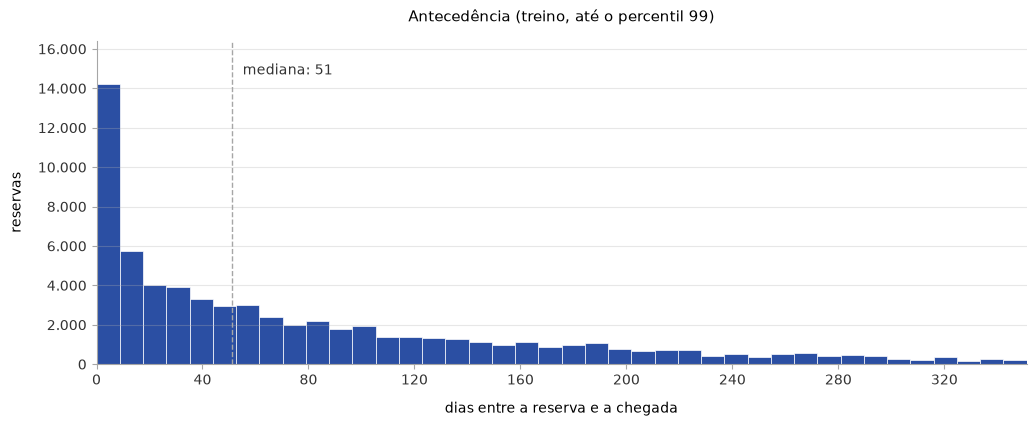

In [4]:
from matplotlib.ticker import FuncFormatter, MaxNLocator, MultipleLocator

milhar = FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.'))   # 14.000, no padrão brasileiro

# a cauda acima do percentil 99 fica fora do gráfico (está na tabela acima)
def histograma(coluna, titulo, rotulo):
    s = treino[coluna]
    limite = s.quantile(0.99)
    bins = np.arange(s.min(), limite + 2) - 0.5 if coluna == 'noites' else 40
    fig, ax = plt.subplots(figsize=(12, 4.2))
    ax.hist(s[s <= limite], bins=bins, color=CORES['principal'], edgecolor='white', linewidth=0.5)
    ax.axvline(s.median(), color=CORES['referencia'], linestyle='--', linewidth=1)
    # rótulo ao lado do topo da linha da mediana, numa folga acima da barra mais alta
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
    ax.annotate(f'mediana: {s.median():.0f}', xy=(s.median(), 0.93), xycoords=ax.get_xaxis_transform(),
                xytext=(8, 0), textcoords='offset points',   # 8 pontos à direita da linha
                fontsize=10, color='#333333', ha='left', va='top',
                bbox=dict(facecolor='white', edgecolor='none', pad=1))
    ax.set_title(f'{titulo} (treino, até o percentil 99)')
    ax.set_xlabel(rotulo)
    ax.set_ylabel('reservas')
    if coluna == 'noites':
        ax.xaxis.set_major_locator(MultipleLocator(1))
        ax.set_xlim(s.min() - 0.5, limite + 0.5)   # o eixo y encosta na primeira barra, centrada no menor valor
    else:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_xlim(0, limite)            # sem folga antes do 0: os eixos se encontram no 0
    ax.yaxis.set_major_formatter(milhar)
    plt.show()


histograma('lead_time', 'Antecedência', 'dias entre a reserva e a chegada')

**Leitura.**

- **`lead_time` tem cauda longa.** Mediana de 51 dias, mas o percentil 99 é 351 e o máximo, 709. 6,3% das reservas são para o próprio dia. Uma reta no logito dificilmente cobre de 0 a 709 dias: confirma a ideia das faixas, a conferir na bivariada.

#### Noites

Uma barra por número de noites, no treino, a partir de 1 noite (as reservas com zero noites saíram da base: notebook 01, seção 4.4). O gráfico vai até o percentil 99 (14 noites): o 1% de reservas mais longas, até o máximo de 69 noites, fica de fora para não achatar o desenho, e aparece no resumo acima.

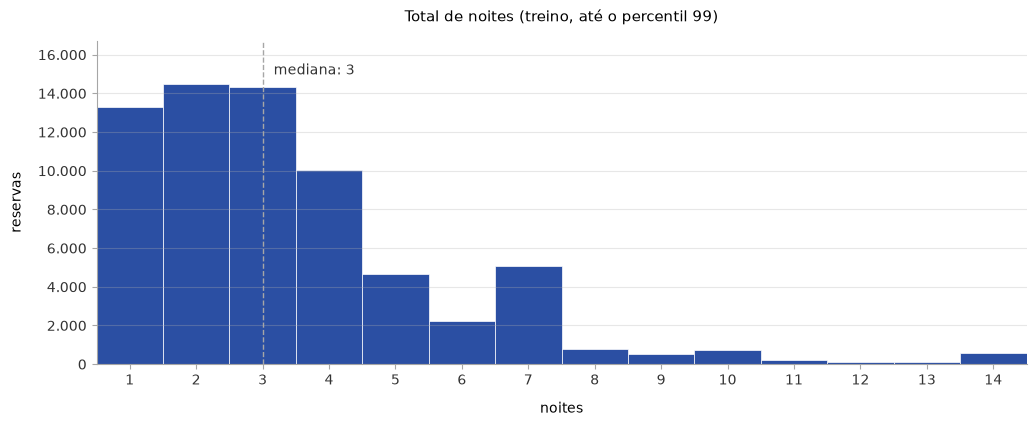

In [5]:
histograma('noites', 'Total de noites', 'noites')

**Leitura.**

- **`noites`: metade das reservas fica de 2 a 4 noites** (p25 e p75), com mediana de 3 e percentil 99 de 14. O pico em 7 é a semana fechada. Faixas de 1, 2–3, 4–7 e mais de 7 noites acompanham esse desenho.

#### Diária

Histograma no treino. O gráfico vai até o percentil 99 (240 €): o 1% de reservas com diária maior, até o máximo de 508 €, fica de fora para não achatar o desenho, e aparece no resumo acima.

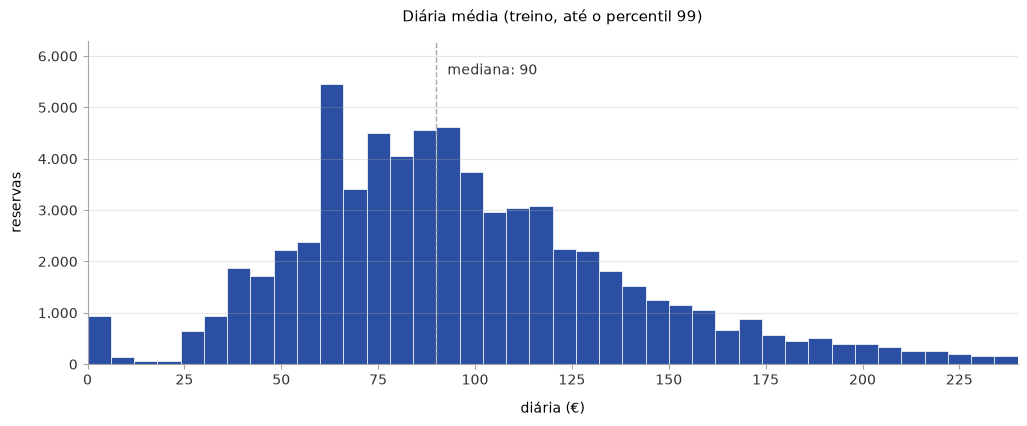

In [6]:
histograma('adr', 'Diária média', 'diária (€)')

**Leitura.**

- **`adr` concentra-se entre 66 e 120** (p25 e p75), com mediana de 90, percentil 99 de 240 e máximo de 508. 1,3% das reservas têm diária zero, que aparece como pico à esquerda no gráfico.

### 2.2 Categóricas

#### Frequências

No treino, marcando as que ficam abaixo de 1%.

In [7]:
categoricas = ['hotel', 'market_segment', 'distribution_channel', 'customer_type', 'meal',
               'reserved_room_type', 'is_repeated_guest']

frequencias = pd.concat({
    c: treino[c].value_counts().rename('reservas').to_frame().assign(pct=lambda t: t['reservas'] / t['reservas'].sum())
    for c in categoricas
})
frequencias.index.names = ['variavel', 'nivel']
frequencias['abaixo_de_1pct'] = frequencias['pct'] < 0.01
frequencias.round(4)

variavel,nivel,reservas,pct,abaixo_de_1pct
hotel,City Hotel,42437,0.6291,False
hotel,Resort Hotel,25018,0.3709,False
market_segment,Online TA,33496,0.4966,False
market_segment,Offline TA/TO,14545,0.2156,False
market_segment,Direct,7848,0.1163,False
market_segment,Groups,7401,0.1097,False
market_segment,Corporate,3531,0.0523,False
market_segment,Complementary,509,0.0075,True
market_segment,Aviation,125,0.0019,True
distribution_channel,TA/TO,53910,0.7992,False


**Leitura.**

- **Categorias abaixo de 1% do treino:**
  - `market_segment`: Complementary (0,8%) e Aviation (0,2%). Juntam em "Outros";
  - `customer_type`: Group (344 reservas, 0,5%). Precisa juntar com outra categoria; a bivariada mostra com qual ela se parece;
  - `meal`: Undefined (642, 0,95%) e FB (408, 0,6%). Undefined fica separado ou junta com SC (notebook 01, seção 4.3); FB pode juntar com HB em "com pensão";
  - `reserved_room_type`: C, H e L (L tem 6 reservas). A variável tende a sair: o código do quarto não significa nada para o público;
  - `distribution_channel`: GDS (0,15%) e uma reserva Undefined. A variável tende a sair por repetir o segmento.
- **Referências naturais (a categoria mais frequente):** City Hotel (62,9%), Online TA (49,7%), Transient (68,9%), BB (78,2%).
- **`is_repeated_guest`:** 3,1% de hóspedes que voltam. Pequeno, mas são 2.110 reservas: dá para estimar.

#### Mês de chegada

Quantas reservas o treino tem em cada mês, em cada ano.

In [8]:
# meses: volume por mês de chegada no treino (2015 só tem julho a dezembro)
meses = ['January', 'February', 'March', 'April', 'May', 'June',
         'July', 'August', 'September', 'October', 'November', 'December']
pd.crosstab(pd.Categorical(treino['arrival_date_month'], meses), treino['arrival_date_year'], margins=True)

row_0,2015,2016,All
January,0,2023,2023
February,0,3354,3354
March,0,4192,4192
April,0,4453,4453
May,0,4683,4683
June,0,4285,4285
July,2524,4256,6780
August,3279,4771,8050
September,3894,4624,8518
October,3833,5363,9196


**Leitura.**

- **O treino não pesa os meses por igual.** 2015 só tem julho a dezembro, então esses meses aparecem em dois anos e janeiro a junho, só em 2016. O efeito de janeiro a junho é estimado com um ano só.

## 3. Bivariada

**Pergunta:** como cada candidata se relaciona com o cancelamento, e em que forma ela entra no modelo?

Tudo no **treino** (2015 e 2016, no escopo). O teste (2017) não entra em nenhuma escolha: para saber se uma relação se mantém no tempo, o notebook compara 2015 com 2016.

Na regressão logística, uma variável numérica tem efeito de reta no logito. O gráfico abaixo mostra o logito empírico de cada faixa contra o valor típico da faixa (a mediana): se os pontos caem numa reta, a variável entra como número; se não, vira faixas ou binária. Contínuas são cortadas em decis; contagens, por valor.

Antecedência, noites e diária não são lineares no logito: entram em faixas (seções 3.1 a 3.3). Os cortes das três saem da árvore de decisão. As contagens passam pelo mesmo método, uma por seção (3.4 a 3.9); a 3.7 junta adultos, crianças e bebês. As categóricas estão nas seções 3.10 a 3.18.


### 3.1 Antecedência

#### Logito de p por decil

As reservas são divididas em 10 grupos com o mesmo número de reservas, pela antecedência. Cada ponto é o logito da taxa de cancelamento do grupo, na mediana dos dias. Se os pontos formarem uma reta, a antecedência entra como número.

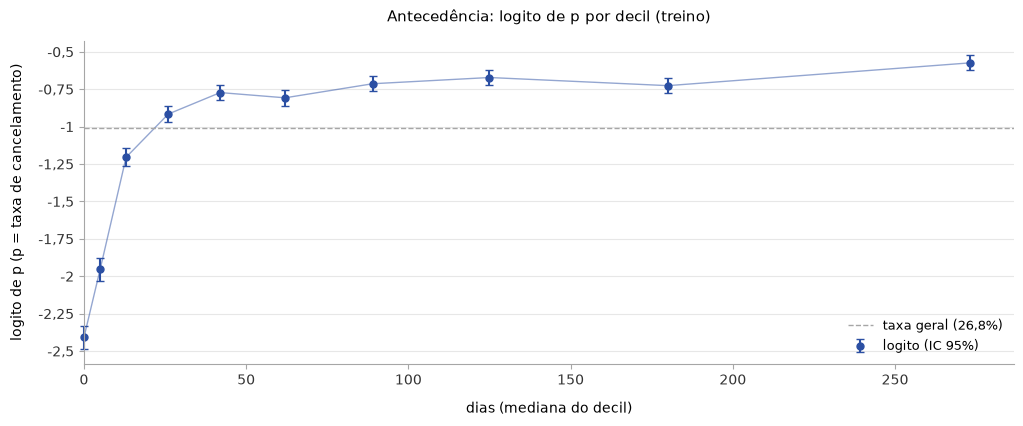

decil,limites,n,taxa,logito,mediana
1,"(-0.001, 2.0]",8057,0.0824,-2.4093,0.0
2,"(2.0, 8.0]",6153,0.1242,-1.9530,5.0
3,"(8.0, 18.0]",6275,0.2306,-1.2047,13.0
4,"(18.0, 34.0]",6904,0.2858,-0.9158,26.0
5,"(34.0, 51.0]",6451,0.3159,-0.7725,42.0
6,"(51.0, 74.0]",6793,0.3084,-0.8075,62.0
7,"(74.0, 104.0]",6587,0.3288,-0.7134,89.0
8,"(104.0, 150.0]",6765,0.3381,-0.6718,125.0
9,"(150.0, 215.0]",6739,0.3260,-0.7262,180.0
10,"(215.0, 709.0]",6731,0.3603,-0.5741,273.0


In [9]:
taxa_treino = treino['is_canceled'].mean()
colunas = ['decil', 'n', 'taxa', 'logito', 'mediana']

def logito_decis(coluna, titulo, rotulo):
    tabela = logito_por_faixa(treino, coluna)
    fig, ax = plt.subplots(figsize=(12, 4.2))
    grafico_logito(tabela, titulo=titulo, rotulo_x=rotulo, taxa_geral=taxa_treino, ax=ax)
    plt.show()
    # decil primeiro e todos os nomes na mesma linha: o índice fica escondido na exibição
    tabela = tabela[colunas].rename_axis('limites').reset_index()
    tabela = tabela[['decil', 'limites', 'n', 'taxa', 'logito', 'mediana']]
    return (tabela.style.hide(axis='index')
                 .format({'taxa': '{:.4f}', 'logito': '{:.4f}', 'mediana': '{:.1f}'}))   # mediana em dias ou euros

logito_decis('lead_time', 'Antecedência: logito de p por decil (treino)',
             'dias (mediana do decil)')

**Leitura.**

- **A antecedência não é linear no logito.** O cancelamento sobe rápido até um mês, de 8,2% (até 2 dias) para 28,6% (19 a 34 dias), e depois quase para: entre 30,8% e 36,0% de 35 a 709 dias. Uma reta não cobre os dois trechos. **Entra em faixas.**

#### Onde cortar: árvore de decisão

A antecedência entra em faixas. Os cortes saem de uma **árvore de decisão com ganho de informação**, usando só a antecedência. O mesmo método vale para as noites, mais abaixo:

1. **A árvore escolhe um corte por vez.** Ela testa todos os cortes possíveis (0 dias, 1 dia, 2 dias...) e fica com o que dá o **maior ganho de informação**: a maior queda na entropia do cancelamento, ou seja, o corte que deixa os grupos menos misturados entre quem cancela e quem vem. Depois, faz o mesmo dentro de cada pedaço.
2. **Regras de parada:**
   - cada faixa precisa ter pelo menos **0,5% do treino** (cerca de 340 reservas), o bastante para estimar a taxa;
   - a árvore para quando o próximo corte traz **menos de 0,0005 de ganho**. Os primeiros cortes trazem ganhos grandes; a partir de certo ponto, os ganhos ficam pequenos e os cortes passam a separar diferenças sem importância.
O desenho mostra a árvore que essas regras produzem: cada pergunta com a parcela das reservas, a taxa de cancelamento e o ganho do corte, e as faixas embaixo. A linha abaixo do desenho mostra por que a árvore parou.

3. **Cada corte precisa valer nos dois anos do treino.** A faixa de cima de um corte precisa cancelar mais que a de baixo em 2015 e em 2016, ou menos nos dois. Se a ordem se inverte entre os anos, o corte sai: primeiro o de menor ganho, e a conferência se repete com as faixas que sobram. 2015 só tem chegadas de julho a dezembro, então parte da diferença entre os anos pode ser época do ano. O teste (2017) não entra nessa conferência.
4. **Comparação:** pelo AIC e pelo BIC, contra a variável como número, o logaritmo, a proposta inicial de faixas e versões com cortes arredondados.

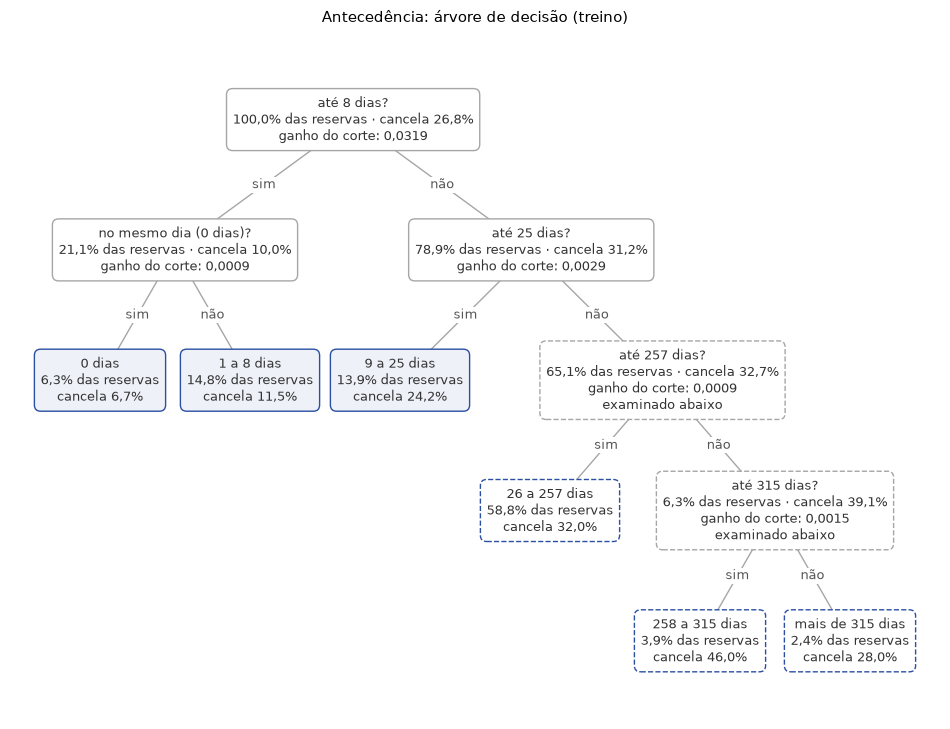

A árvore para em 6 faixas: o próximo corte (251 dias) teria ganho de 0,0004, abaixo do mínimo de 0,0005.


In [10]:
# antecedência: a árvore que as regras de parada produzem (treino)
passos_lead = cortes_por_ganho(treino, 'lead_time')
n_faixas_lead = int((passos_lead['aceito'] == 'sim').sum()) + 1
desenhar_arvore(treino, 'lead_time', n_faixas=n_faixas_lead, unidade='dias', examinar=(257, 315),
                titulo='Antecedência: árvore de decisão (treino)')

# por que a árvore para aqui
parada = passos_lead[passos_lead['aceito'] == 'não'].iloc[0]
ganho_parada = f"{parada['ganho']:.4f}".replace('.', ',')
print(f"A árvore para em {n_faixas_lead} faixas: o próximo corte ({parada['corte_novo']} dias) teria ganho de "
      f"{ganho_parada}, abaixo do mínimo de 0,0005.")

**Leitura.**

- **O primeiro corte, em 8 dias, traz quase todo o ganho** (0,0319). Ele separa as reservas feitas com até 8 dias de antecedência das feitas com 9 dias ou mais.
- **Depois, a árvore subdivide cada lado.** Até 8 dias, separa o mesmo dia da chegada (0,0009). Acima de 8 dias, corta em 25 dias (0,0029), em 257 (0,0009) e em 315 (0,0015). Esses ganhos vão de 0,0009 a 0,0029, contra 0,0319 do primeiro.
- **A árvore para em 6 faixas:** o próximo corte, em 251 dias, teria ganho de 0,0004, abaixo do mínimo.
- **O corte em 315 dias quebra a escada:** em todas as outras faixas, quanto maior a antecedência, maior o cancelamento; acima de 315 dias, a taxa cai.
- **Resultado da árvore: 6 faixas:** no mesmo dia, 1 a 8, 9 a 25, 26 a 257, 258 a 315 e mais de 315 dias. Os cortes são conferidos em 2015 e em 2016, abaixo.

#### Os cortes em 2015 e em 2016

Taxa de cada faixa em cada ano do treino. Em cada rodada, a coluna `mesma_ordem` diz se a faixa fica acima (ou abaixo) da anterior nos dois anos. O corte que inverte sai, e a rodada seguinte confere as faixas que sobram.

In [11]:
# antecedência: os cortes da árvore valem em 2015 e em 2016? (só o treino)
cortes_lead, conferencia_lead, saidas_lead = conferir_cortes_por_periodo(treino, 'lead_time', passos_lead)
display(conferencia_lead.round(4))
print('\n'.join(saidas_lead))
print('Cortes que ficam:', cortes_lead)

rodada,faixa,taxa_2015,taxa_2016,mesma_ordem
1,0,0.0677,0.0665,
1,1–8,0.1128,0.1157,sim
1,9–25,0.1834,0.2678,sim
1,26–257,0.2720,0.3363,sim
1,258–315,0.6177,0.3412,sim
1,mais de 315,0.8255,0.1879,não
2,0,0.0677,0.0665,
2,1–8,0.1128,0.1157,sim
2,9–25,0.1834,0.2678,sim
2,26–257,0.2720,0.3363,sim


Rodada 1: o corte em 315 inverte a ordem entre os períodos e sai.
Rodada 2: o corte em 257 inverte a ordem entre os períodos e sai.
Cortes que ficam: [0, 8, 25]


**Leitura.**

- **Rodada 1: o corte em 315 dias inverte.** Em 2015, acima de 315 dias cancela 82,6%, mais que de 258 a 315 (61,8%); em 2016, cancela 18,8%, menos que de 258 a 315 (34,1%). **Sai.**
- **Rodada 2: o corte em 257 dias também inverte.** Acima de 257 dias, 65,4% em 2015 e 26,7% em 2016, contra 27,2% e 33,6% de 26 a 257 dias. **Sai.**
- **Rodada 3: os cortes que sobram valem nos dois anos:** 0, 1–8, 9–25 e mais de 25 dias, em escada em 2015 e em 2016.

#### Quem reserva com mais de 257 dias

Parcela de grupos e operadoras, de linhas idênticas e de 2015 nas reservas com mais de 257 dias, comparadas com as demais.

In [12]:
# quem reserva com mais de 257 dias de antecedência? (treino)
faixa_cauda = pd.cut(treino['lead_time'], [-1, 257, 315, np.inf], labels=['até 257', '258–315', 'mais de 315'])
treino.groupby(faixa_cauda, observed=True).agg(
    reservas=('is_canceled', 'size'),
    pct_grupo_ou_operadora=('market_segment', lambda s: s.isin(['Groups', 'Offline TA/TO']).mean()),
    pct_com_linha_identica=('tem_gemea', 'mean'),
    pct_2015=('arrival_date_year', lambda s: (s == 2015).mean()),
).rename_axis('antecedencia').round(4)

antecedencia,reservas,pct_grupo_ou_operadora,pct_com_linha_identica,pct_2015
até 257,63227,0.2927,0.2393,0.2656
258–315,2609,0.7558,0.6777,0.4281
mais de 315,1619,0.9055,0.6720,0.1452


**Leitura.**

- **Acima de 257 dias, quase tudo é grupo ou operadora:** 75,6% de 258 a 315 dias e 90,5% acima de 315, contra 29,3% até 257. Cerca de dois terços têm linha idêntica: são blocos de quartos.
- **Acima de 257 dias, a taxa cai de 65,4% em 2015 para 26,7% em 2016** (conferência acima). Com tantos blocos, os cortes nessa ponta medem o que aconteceu com alguns grupos, e não o efeito da antecedência.

#### Comparação das opções de corte

Cada opção vira um modelo só com a antecedência, e as opções são comparadas pelo AIC e pelo BIC: nos dois, quanto menor, melhor, e as colunas `dif_` dão a distância para a melhor opção. Entram a árvore inteira, a árvore conferida em 2015 e 2016, uma versão com cortes arredondados, a proposta inicial de faixas, a antecedência como número, o logaritmo e o modelo sem nenhuma variável.

In [13]:
# antecedência: as faixas da árvore comparadas com as outras opções (treino)
opcoes_lead = {
    'árvore inteira: 0 / 1–8 / 9–25 / 26–257 / 258–315 / mais de 315': [-1, 0, 8, 25, 257, 315, np.inf],
    'árvore conferida em 2015 e 2016: 0 / 1–8 / 9–25 / mais de 25': [-1, 0, 8, 25, np.inf],
    'arredondada: 0 / 1–7 / 8–30 / mais de 30': [-1, 0, 7, 30, np.inf],
    'proposta inicial: até 7 / 8–30 / 31–90 / 91–180 / mais de 180': [-1, 7, 30, 90, 180, np.inf],
}
comparar_cortes(treino, 'lead_time', opcoes_lead, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'antecedência como número': 'is_canceled ~ lead_time',
    'logaritmo da antecedência': 'is_canceled ~ np.log1p(lead_time)',
})

opcao,faixas,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,menor_faixa,taxa_por_faixa
árvore inteira: 0 / 1–8 / 9–25 / 26–257 / 258–315 / mais de 315,6,5,74832.4000,0,74887.1000,0,0.0240,"6,7% / 11,5% / 24,2% / 32,0% / 46,0% / 28,0%"
árvore conferida em 2015 e 2016: 0 / 1–8 / 9–25 / mais de 25,4,3,75050.2000,217.7000,75086.6000,199.5000,0.0632,"6,7% / 11,5% / 24,2% / 32,7%"
arredondada: 0 / 1–7 / 8–30 / mais de 30,4,3,75100,267.6000,75136.5000,249.3000,0.0632,"6,7% / 11,0% / 25,0% / 32,8%"
proposta inicial: até 7 / 8–30 / 31–90 / 91–180 / mais de 180,5,4,75103.1000,270.7000,75148.7000,261.5000,0.1489,"9,7% / 25,0% / 30,9% / 33,5% / 35,5%"
logaritmo da antecedência,,1,75387.4000,555,75405.6000,518.5000,,
antecedência como número,,1,77129.8000,2297.4000,77148,2260.9000,,
sem nenhuma variável,,0,78375.6000,3543.2000,78384.7000,3497.6000,,


**Leitura.**

- **As faixas vencem a antecedência como número com folga:** o número fica 2.260,9 pontos de BIC atrás da melhor opção, e o logaritmo, 518,5.
- **A árvore inteira é a melhor pelo AIC e pelo BIC**, 199,5 pontos de BIC à frente da árvore conferida. Mas os cortes que fazem essa diferença, em 257 e 315 dias, invertem entre 2015 e 2016. A comparação mede o ajuste no treino inteiro e não vê isso.
- **A árvore conferida ganha das outras opções:** a versão com cortes arredondados (0, 7 e 30 dias) fica 49,8 pontos de BIC atrás dela, e a proposta inicial, 62,0. Arredondar os cortes custa caro: 8 e 25 dias separam melhor que 7 e 30.
- **Proposta: as 4 faixas da árvore conferida:** no mesmo dia (0), 1–8, 9–25 e mais de 25 dias.

#### Faixas finais

Taxa de cancelamento de cada faixa no treino, com o intervalo de confiança, e em cada ano do treino, para conferir se a ordem se mantém.

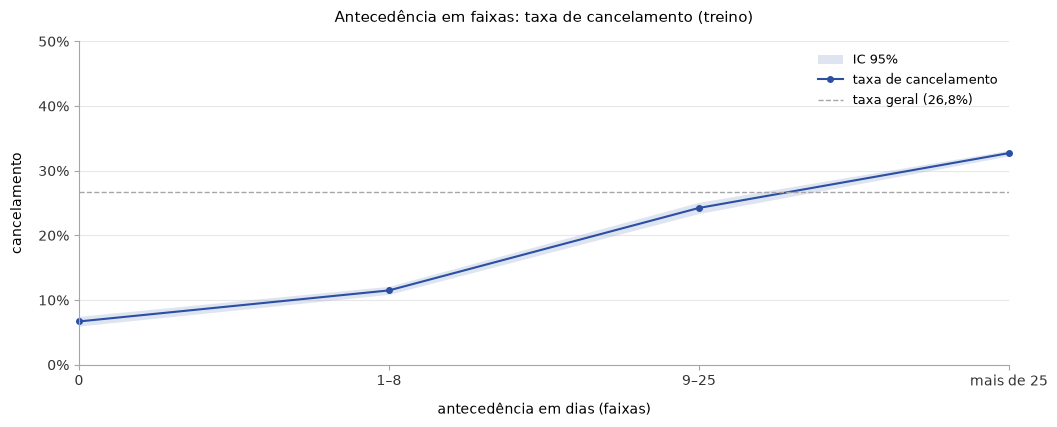

lead_time,n,pct_base,taxa,ic_inf,ic_sup,taxa_2015,taxa_2016
0,4260,0.0632,0.0669,0.0598,0.0748,0.0677,0.0665
1–8,9950,0.1475,0.1149,0.1088,0.1213,0.1128,0.1157
9–25,9353,0.1387,0.2424,0.2338,0.2512,0.1834,0.2678
mais de 25,43892,0.6507,0.3272,0.3228,0.3316,0.3182,0.3303


In [14]:
# faixas escolhidas: taxa no treino (com intervalo) e em cada ano do treino, que precisa manter a ordem
def conferir_faixas(variavel, limites, rotulos, titulo, rotulo_x):
    faixa = pd.cut(treino[variavel], limites, labels=rotulos)
    tabela = taxa_por_nivel(treino.assign(faixa=faixa), 'faixa')[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']]
    por_ano = treino.groupby([faixa, 'arrival_date_year'], observed=True)['is_canceled'].mean().unstack()
    tabela[['taxa_2015', 'taxa_2016']] = por_ano[[2015, 2016]].to_numpy()
    ax = grafico_taxa_por_nivel(tabela, taxa_geral=taxa_treino, linha=True, titulo=titulo)
    ax.figure.set_size_inches(12, 4.2)
    ax.set_ylim(0, 0.5)
    ax.set_xlabel(rotulo_x)
    plt.show()
    return tabela.rename_axis(variavel).round(4)

# limites para o pd.cut (cada faixa inclui o limite da direita; o -1 serve para incluir o 0):
#   (-1, 0] = 0 dias | (0, 8] = 1 a 8 | (8, 25] = 9 a 25 | (25, inf) = mais de 25
faixas_lead = [-1, 0, 8, 25, np.inf]
rotulos_lead = ['0', '1–8', '9–25', 'mais de 25']
conferir_faixas('lead_time', faixas_lead, rotulos_lead,
                'Antecedência em faixas: taxa de cancelamento (treino)',
                'antecedência em dias (faixas)')

**Leitura.**

- **A taxa sobe nas quatro faixas:** 6,7% no mesmo dia, 11,5% de 1 a 8 dias, 24,2% de 9 a 25 e 32,7% acima de 25. Os intervalos de faixas vizinhas não se tocam.
- **A ordem se mantém nos dois anos:** 6,8%, 11,3%, 18,3% e 31,8% em 2015; 6,7%, 11,6%, 26,8% e 33,0% em 2016.
- **Referência: mais de 25 dias**, a maior (65,1% do treino).
- **Para a apresentação:** "no mesmo dia", "até uma semana", "até três semanas" e "mais de três semanas".

### 3.2 Noites

#### Logito de p por valor

Um ponto por número de noites; o último junta a cauda. Se os pontos formarem uma reta, as noites entram como número.

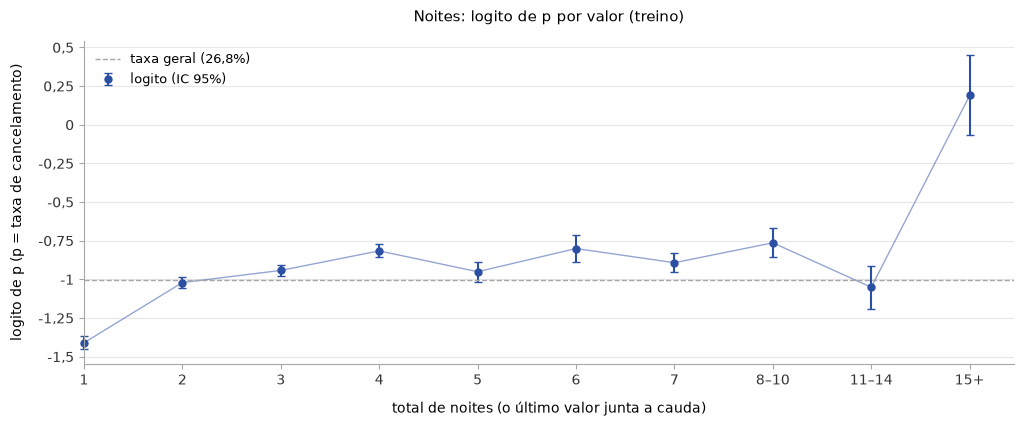

noites,n,taxa,ic_inf,ic_sup
1,13318,0.1961,0.1895,0.2030
2,14477,0.2649,0.2578,0.2722
3,14350,0.2804,0.2731,0.2878
4,10025,0.3066,0.2977,0.3157
5,4657,0.2787,0.2660,0.2918
6,2250,0.3098,0.2910,0.3292
7,5055,0.2906,0.2782,0.3033
8–10,2036,0.3178,0.2979,0.3383
11–14,1055,0.2588,0.2332,0.2860
15+,232,0.5474,0.4831,0.6102


In [15]:
# noites: logito de p por valor (treino); o último valor junta a cauda
limites_valor_noites = [0, 1, 2, 3, 4, 5, 6, 7, 10, 14, np.inf]
rotulos_valor_noites = ['1', '2', '3', '4', '5', '6', '7', '8–10', '11–14', '15+']
tabela_noites = logito_por_faixa(treino, 'noites', limites=limites_valor_noites)
tabela_noites.index = rotulos_valor_noites

fig, ax = plt.subplots(figsize=(12, 4.2))
grafico_logito(tabela_noites, titulo='Noites: logito de p por valor (treino)',
               rotulo_x='total de noites (o último valor junta a cauda)', taxa_geral=taxa_treino,
               posicao=range(len(rotulos_valor_noites)), ax=ax)
ax.set_xticks(range(len(rotulos_valor_noites)), rotulos_valor_noites)
plt.show()

tabela_noites[['n', 'taxa', 'ic_inf', 'ic_sup']].rename_axis('noites').round(4)

**Leitura.**

- **Uma noite cancela bem menos:** 19,6% com uma noite; de 2 a 14 noites, a taxa fica entre 25,9% e 31,8%. 15 noites ou mais cancelam 54,7%, mas são só 232. Não é linear no logito: **entra em faixas**.

#### Onde cortar: árvore de decisão

Mesmo método da antecedência: a árvore de decisão com ganho de informação escolhe os cortes, com as mesmas regras de parada (pelo menos 0,5% do treino por faixa e ganho mínimo de 0,0005 por corte), e as faixas são comparadas pelo AIC e pelo BIC. As reservas com zero noites já saíram da base (notebook 01, seção 4.4).

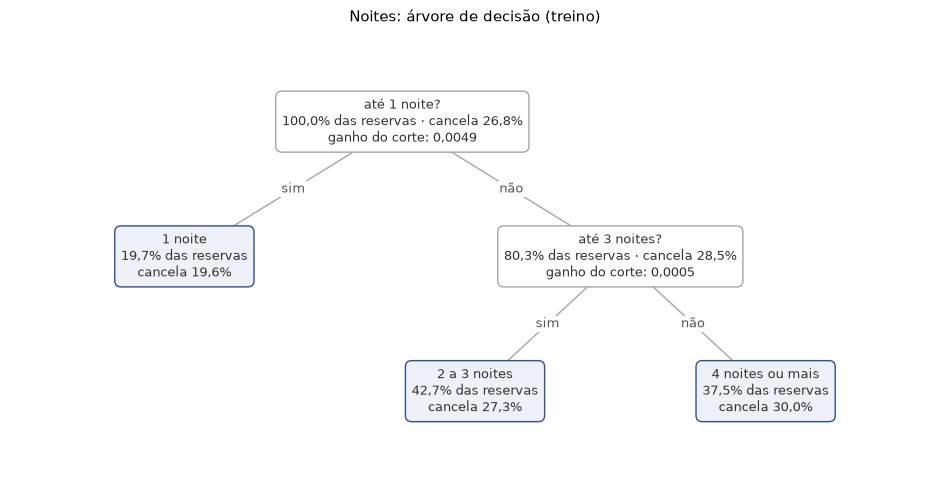

A árvore para em 3 faixas: o próximo corte (2 noites) teria ganho de 0,0001, abaixo do mínimo de 0,0005.


In [16]:
# noites: a árvore que as regras de parada produzem (treino), com o mesmo método da antecedência
passos_noites = cortes_por_ganho(treino, 'noites')
n_faixas_noites = int((passos_noites['aceito'] == 'sim').sum()) + 1
desenhar_arvore(treino, 'noites', n_faixas=n_faixas_noites, unidade='noites', ultima='ou mais',
                titulo='Noites: árvore de decisão (treino)')

# por que a árvore para aqui
parada = passos_noites[passos_noites['aceito'] == 'não'].iloc[0]
ganho_parada = f"{parada['ganho']:.4f}".replace('.', ',')
print(f"A árvore para em {n_faixas_noites} faixas: o próximo corte ({parada['corte_novo']} noites) teria ganho de "
      f"{ganho_parada}, abaixo do mínimo de 0,0005.")

**Leitura.**

- **O primeiro corte separa 1 noite das demais** (ganho de 0,0049).
- **Depois, acima de 1 noite, a árvore separa 2–3 de 4 ou mais** (0,0005).
- **A árvore para em 3 faixas:** o próximo corte, entre 2 e 3 noites, teria ganho de 0,0001, abaixo do mínimo.
- **Resultado: 3 faixas:** 1, 2–3 e 4 ou mais noites.

#### Comparação das opções de corte

Como na antecedência: a árvore, a proposta inicial de faixas, as noites como número, o logaritmo e o modelo sem nenhuma variável, comparados pelo AIC e pelo BIC.

In [17]:
# noites: as faixas da árvore comparadas com as outras opções (treino)
opcoes_noites = {
    'árvore: 1 / 2–3 / 4 ou mais': [0, 1, 3, np.inf],
    'proposta inicial: 1 / 2–3 / 4–7 / mais de 7': [0, 1, 3, 7, np.inf],
}
comparar_cortes(treino, 'noites', opcoes_noites, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'noites como número': 'is_canceled ~ noites',
    'logaritmo das noites': 'is_canceled ~ np.log1p(noites)',
})

opcao,faixas,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,menor_faixa,taxa_por_faixa
proposta inicial: 1 / 2–3 / 4–7 / mais de 7,4,3,77873.3000,0,77909.8000,6.8000,0.0493,"19,6% / 27,3% / 29,7% / 31,5%"
árvore: 1 / 2–3 / 4 ou mais,3,2,77875.6000,2.3000,77902.9000,0,0.1974,"19,6% / 27,3% / 30,0%"
logaritmo das noites,,1,77999,125.7000,78017.3000,114.3000,,
noites como número,,1,78135.9000,262.6000,78154.1000,251.2000,,
sem nenhuma variável,,0,78375.6000,502.3000,78384.7000,481.8000,,


**Leitura.**

- **A árvore (1 / 2–3 / 4 ou mais) e a proposta inicial (1 / 2–3 / 4–7 / mais de 7) quase empatam.** Pelo AIC, a proposta inicial fica 2,3 pontos à frente; pelo BIC, a árvore fica 6,8 pontos à frente. A separação extra entre 4–7 e mais de 7 noites não se sustenta pelo BIC, e fica a versão mais simples.
- **Noites como número fica 251,2 pontos de BIC atrás**, e o logaritmo, 114,3.
- **Proposta: as 3 faixas da árvore:** 1, 2–3 e 4 ou mais noites.

#### Faixas finais

Taxa de cada faixa no treino, com o intervalo de confiança, e em cada ano do treino.

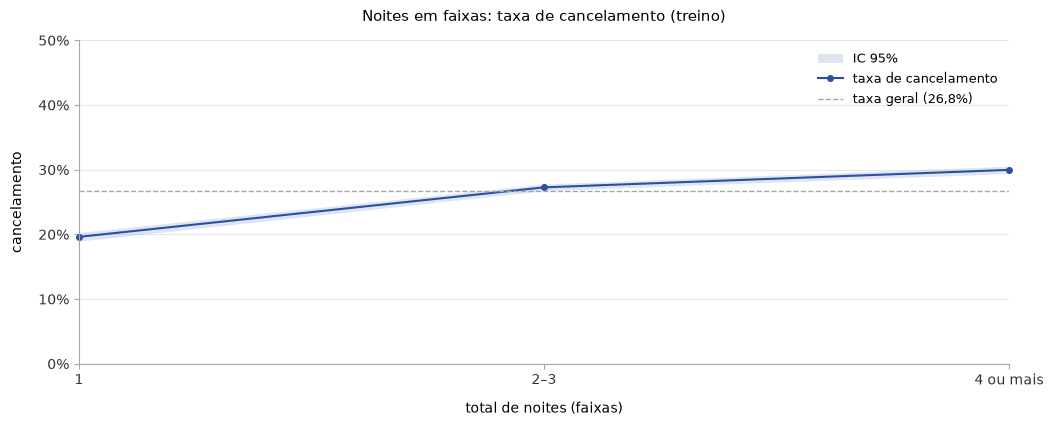

noites,n,pct_base,taxa,ic_inf,ic_sup,taxa_2015,taxa_2016
1,13318,0.1974,0.1961,0.1895,0.2030,0.1435,0.2116
2–3,28827,0.4274,0.2726,0.2675,0.2778,0.2636,0.2762
4 ou mais,25310,0.3752,0.2997,0.2941,0.3054,0.2720,0.3101


In [18]:
# limites para o pd.cut (cada faixa inclui o limite da direita):
#   (0, 1] = 1 noite | (1, 3] = 2 a 3 | (3, inf) = 4 ou mais
faixas_noites = [0, 1, 3, np.inf]
rotulos_noites = ['1', '2–3', '4 ou mais']
conferir_faixas('noites', faixas_noites, rotulos_noites,
                'Noites em faixas: taxa de cancelamento (treino)',
                'total de noites (faixas)')

**Leitura.**

- **A taxa sobe nas três faixas:** 19,6% com 1 noite, 27,3% com 2–3 e 30,0% com 4 ou mais. Os intervalos de faixas vizinhas não se tocam.
- **A ordem se mantém nos dois anos:** 14,4%, 26,4% e 27,2% em 2015; 21,2%, 27,6% e 31,0% em 2016. Nenhum corte sai.
- **Referência: 2–3 noites**, a maior (42,7% do treino).

### 3.3 Diária

#### Logito de p por decil

Abaixo, o primeiro decil separado entre diária zero e diária positiva.

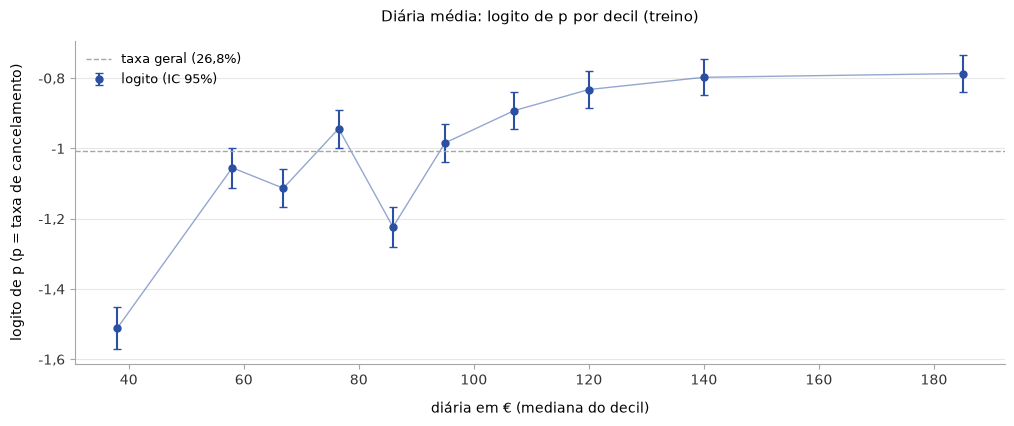

decil,limites,n,taxa,logito,mediana
1,"(-0.001, 48.0]",7140,0.1807,-1.5115,38.0
2,"(48.0, 62.538]",6351,0.2582,-1.0550,58.0
3,"(62.538, 72.25]",6929,0.2472,-1.1133,66.9
4,"(72.25, 80.75]",6583,0.2801,-0.9437,76.5
5,"(80.75, 90.0]",6776,0.2273,-1.2235,85.9
6,"(90.0, 100.0]",6724,0.2720,-0.9843,95.0
7,"(100.0, 113.6]",6725,0.2906,-0.8925,107.0
8,"(113.6, 129.6]",6747,0.3031,-0.8325,120.0
9,"(129.6, 157.0]",6760,0.3105,-0.7976,140.0
10,"(157.0, 508.0]",6720,0.3128,-0.7869,185.0


O primeiro decil vai até 48.00 €


faixa_adr,n,pct_base,taxa,ic_inf,ic_sup
zero,877,0.0130,0.1460,0.1241,0.1709
"positiva, no decil 1",6263,0.0928,0.1855,0.1761,0.1954
acima do decil 1,60315,0.8942,0.2780,0.2744,0.2816


In [19]:
display(logito_decis('adr', 'Diária média: logito de p por decil (treino)',
                     'diária em € (mediana do decil)'))

# o primeiro decil da diária inclui as diárias zero (notebook 01, seção 4.3); o limite sai do próprio decil
limite_decil_1 = pd.qcut(treino['adr'], 10, duplicates='drop').cat.categories[0].right
print(f'O primeiro decil vai até {limite_decil_1:.2f} €')
rotulos_decil_1 = ['zero', 'positiva, no decil 1', 'acima do decil 1']
taxa_por_nivel(treino.assign(faixa_adr=pd.cut(treino['adr'], [-1, 0, limite_decil_1, np.inf], labels=rotulos_decil_1)),
               'faixa_adr')[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']].round(4)

**Leitura.**

- **A diária também não é linear.** O primeiro decil (até 48 €) cancela 18,1%. As 877 diárias zero cancelam 14,6%, e as 6.263 positivas do decil, 18,6%: o decil cancela pouco mesmo sem as diárias zero. Entre 48 e 100, a taxa oscila de 22,7% a 28,0%, sem escada; acima de 114, fica perto de 31%. **Entra em faixas.**

#### Onde cortar: árvore de decisão

Mesmo método da antecedência e das noites, com as mesmas regras de parada (pelo menos 0,5% do treino por faixa e ganho mínimo de 0,0005 por corte). A árvore trabalha com valores inteiros, e a diária tem centavos: ela é arredondada para o euro mais próximo (coluna `diaria_euro`). Os cortes passam por duas conferências: a largura mínima das faixas e os dois anos do treino.

Diárias com centavos no treino: 47.7%


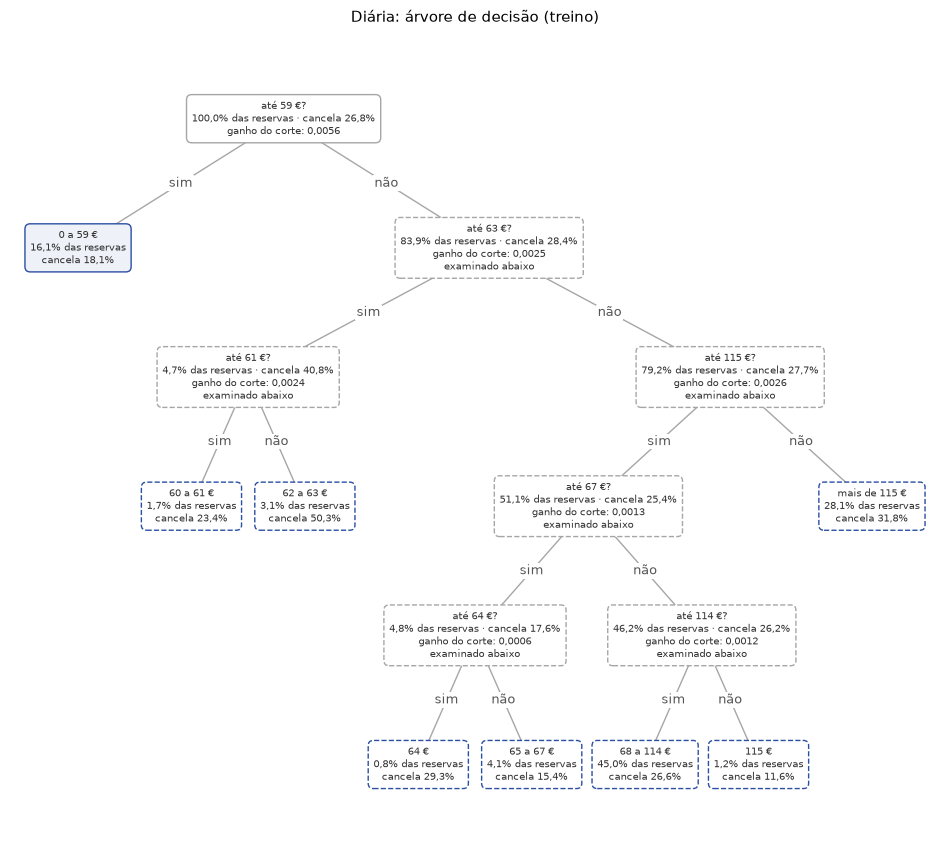

A árvore para em 8 faixas: o próximo corte (93 €) teria ganho de 0,00048, abaixo do mínimo de 0,0005.


In [20]:
# diária: arredondada para o euro, porque a árvore trabalha com valores inteiros
print(f"Diárias com centavos no treino: {(treino['adr'] != treino['adr'].round()).mean():.1%}")
treino = treino.assign(diaria_euro=treino['adr'].round())

# a árvore que as regras de parada produzem (treino); os cortes destacados saem nas conferências abaixo
passos_adr = cortes_por_ganho(treino, 'diaria_euro')
n_faixas_adr = int((passos_adr['aceito'] == 'sim').sum()) + 1
desenhar_arvore(treino, 'diaria_euro', n_faixas=n_faixas_adr, unidade='€', examinar=(61, 63, 64, 67, 114, 115),
                titulo='Diária: árvore de decisão (treino)')

# por que a árvore para aqui
parada = passos_adr[passos_adr['aceito'] == 'não'].iloc[0]
ganho_parada = f"{parada['ganho']:.5f}".replace('.', ',')   # 5 casas: com 4, o ganho sairia igual ao mínimo
print(f"A árvore para em {n_faixas_adr} faixas: o próximo corte ({parada['corte_novo']} €) teria ganho de "
      f"{ganho_parada}, abaixo do mínimo de 0,0005.")

**Leitura.**

- **O primeiro corte, em 59 €, traz o maior ganho** (0,0056). Ele separa as diárias de até 59 € das maiores.
- **Os cortes seguintes criam faixas de 1 a 3 euros:** 60–61, 62–63, 64, 65–67 e 115 €. Ao lado delas ficam três faixas largas: até 59, 68–114 e mais de 115 €.
- **A árvore para em 8 faixas:** o próximo corte, em 93 €, teria ganho de 0,00048, abaixo do mínimo.
- **Faixas de 1 a 3 euros não medem nível de preço.** Abaixo, quem são essas reservas e as duas conferências.

#### Os preços mais comuns nas faixas estreitas

As 8 combinações de diária exata, hotel e segmento com mais reservas nas faixas estreitas da árvore (60 a 67 € e 115 €).

In [21]:
# faixas estreitas: as diárias exatas mais comuns (treino)
estreitas = treino[treino['diaria_euro'].between(60, 67) | (treino['diaria_euro'] == 115)]
print(f"Reservas nas faixas estreitas: {len(estreitas)} ({len(estreitas) / len(treino):.1%} do treino)")
(estreitas.groupby(['adr', 'hotel', 'market_segment'])['is_canceled'].agg(reservas='size', taxa='mean')
 .sort_values('reservas', ascending=False).head(8).round(4))

Reservas nas faixas estreitas: 7285 (10.8% do treino)


adr,hotel,market_segment,reservas,taxa
62,City Hotel,Groups,1226,0.5408
65,City Hotel,Corporate,542,0.0978
115,City Hotel,Offline TA/TO,494,0.0162
65,City Hotel,Groups,392,0.1837
60,City Hotel,Offline TA/TO,258,0.2984
62.8000,City Hotel,Groups,241,1
60,City Hotel,Groups,232,0.2845
65,City Hotel,Offline TA/TO,222,0.1036


**Leitura.**

- **Cada faixa estreita é puxada por uma tarifa.** A 62 €, 1.226 reservas de grupos do hotel urbano cancelam 54,1%; a 62,80 €, 241 reservas de grupos cancelam todas. A 115 €, 494 reservas de operadora cancelam 1,6%. A 65 €, 542 reservas corporativas cancelam 9,8%.
- **São tarifas de grupos, operadoras e empresas, e não níveis de preço.** Grupos e operadoras já entram pelo segmento (seção 3.11). A largura mínima, abaixo, tira esses cortes.

#### Largura mínima das faixas

A árvore criou faixas que cobrem só 1 a 3 euros de diária (por exemplo, de 62 a 63 €), puxadas por tarifas de grupos, operadoras e empresas, e não por níveis de preço (acima). Para que cada faixa represente um nível de preço, a análise adota uma largura mínima de 10 euros. Entre os cortes que criam faixas mais estreitas, sai o de menor ganho, e a conferência se repete até todas as faixas terem a largura mínima. A última faixa, aberta, não conta.

In [22]:
# diária: tira os cortes que criam faixas com menos de 10 euros (treino)
passos_adr_largos, saidas_largura = conferir_largura_minima(treino, 'diaria_euro', passos_adr, largura=10)
print('\n'.join(saidas_largura))
print('Cortes que ficam:', sorted(passos_adr_largos['corte_novo'].astype(int)))

O corte em 64 cria uma faixa com menos de 10 valores e sai.
O corte em 114 cria uma faixa com menos de 10 valores e sai.
O corte em 67 cria uma faixa com menos de 10 valores e sai.
O corte em 61 cria uma faixa com menos de 10 valores e sai.
O corte em 63 cria uma faixa com menos de 10 valores e sai.
Cortes que ficam: [59, 115]


**Leitura.**

- **Saem cinco cortes, um por vez:** 64, 114, 67, 61 e 63 €.
- **Ficam dois: 59 e 115 €**, com as faixas até 59, 60–115 e mais de 115 €.

#### Os cortes em 2015 e em 2016

Como nas outras variáveis: a taxa de cada faixa em cada ano do treino, com uma rodada por corte que sai.

In [23]:
# diária: os cortes que sobram valem em 2015 e em 2016? (só o treino)
cortes_adr, conferencia_adr, saidas_adr = conferir_cortes_por_periodo(treino, 'diaria_euro', passos_adr_largos)
display(conferencia_adr.round(4))
print('\n'.join(saidas_adr))
print('Cortes que ficam:', cortes_adr)

rodada,faixa,taxa_2015,taxa_2016,mesma_ordem
1,0–59,0.2055,0.1697,
1,60–115,0.2671,0.2673,sim
1,mais de 115,0.2276,0.3412,não
2,0–59,0.2055,0.1697,
2,mais de 59,0.2567,0.2939,sim


Rodada 1: o corte em 115 inverte a ordem entre os períodos e sai.
Cortes que ficam: [59]


**Leitura.**

- **Rodada 1: o corte em 115 € inverte.** Acima de 115 €, a reserva cancela 22,8% em 2015, menos que de 60 a 115 € (26,7%), e 34,1% em 2016, mais (26,7%). O preço sobe de um ano para o outro, e "mais de 115 €" passa a juntar reservas diferentes. **Sai.**
- **Rodada 2: o corte em 59 € vale nos dois anos:** até 59 € cancela 20,6% em 2015 e 17,0% em 2016, contra 25,7% e 29,4% acima. **Fica.**

#### Comparação das opções de corte

Cada opção vira um modelo só com a diária, comparado pelo AIC e pelo BIC. Entram a árvore inteira, a árvore só com a largura mínima, a árvore conferida (largura e anos), a diária como número, o logaritmo e o modelo sem nenhuma variável.

In [24]:
# diária: as opções comparadas (treino)
opcoes_adr = {
    'árvore inteira: 8 faixas': [-1, 59, 61, 63, 64, 67, 114, 115, np.inf],
    'só com a largura mínima: até 59 / 60–115 / mais de 115': [-1, 59, 115, np.inf],
    'árvore conferida (largura e anos): até 59 / mais de 59': [-1, 59, np.inf],
}
comparar_cortes(treino, 'diaria_euro', opcoes_adr, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'diária como número': 'is_canceled ~ adr',
    'logaritmo da diária': 'is_canceled ~ np.log1p(adr)',
})

opcao,faixas,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,menor_faixa,taxa_por_faixa
árvore inteira: 8 faixas,8,7,76861.7000,0,76934.6000,0,0.0076,"18,1% / 23,4% / 50,3% / 29,3% / 15,4% / 26,6% / 11,6% / 31,8%"
só com a largura mínima: até 59 / 60–115 / mais de 115,3,2,77694.1000,832.4000,77721.4000,786.8000,0.1610,"18,1% / 26,7% / 31,8%"
árvore conferida (largura e anos): até 59 / mais de 59,2,1,77850.4000,988.7000,77868.6000,934,0.1610,"18,1% / 28,4%"
logaritmo da diária,,1,77992.6000,1130.9000,78010.8000,1076.2000,,
diária como número,,1,78006,1144.3000,78024.2000,1089.6000,,
sem nenhuma variável,,0,78375.6000,1513.9000,78384.7000,1450.1000,,


**Leitura.**

- **A árvore inteira é a melhor pelo AIC e pelo BIC**, mas seus cortes estreitos são tarifas, e o de 115 € inverte entre os anos.
- **A árvore conferida fica 934,0 pontos de BIC atrás da inteira**, e a versão só com a largura mínima, 786,8. É o preço de tirar as tarifas e o corte instável.
- **A árvore conferida ganha das outras opções:** a diária como número fica 155,6 pontos de BIC atrás dela, e o logaritmo, 142,2.
- **Proposta: até 59 € × mais de 59 €.**

#### Faixas finais

Taxa de cada faixa no treino, com o intervalo de confiança, e em cada ano do treino.

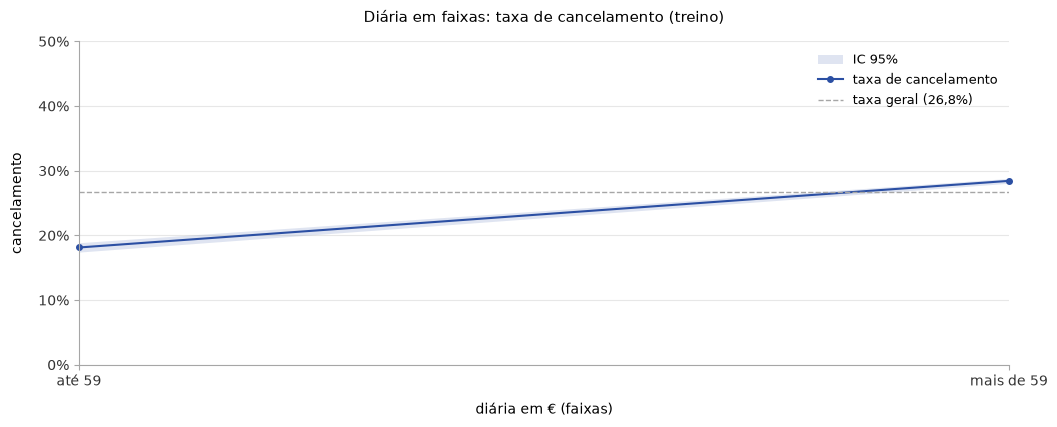

diaria_euro,n,pct_base,taxa,ic_inf,ic_sup,taxa_2015,taxa_2016
até 59,10858,0.1610,0.1812,0.1741,0.1886,0.2055,0.1697
mais de 59,56597,0.8390,0.2843,0.2806,0.2880,0.2567,0.2939


In [25]:
# limites para o pd.cut (cada faixa inclui o limite da direita; o -1 serve para incluir o 0):
#   (-1, 59] = até 59 € | (59, inf) = mais de 59 €
conferir_faixas('diaria_euro', [-1, 59, np.inf], ['até 59', 'mais de 59'],
                'Diária em faixas: taxa de cancelamento (treino)', 'diária em € (faixas)')

**Leitura.**

- **Diárias até 59 € cancelam 18,1%, contra 28,4% acima.** Os intervalos não se tocam.
- **A ordem se mantém nos dois anos:** 20,6% e 25,7% em 2015; 17,0% e 29,4% em 2016.
- **Referência: mais de 59 €**, a maior (83,9% do treino).
- **Faixas em euros envelhecem:** a diária mediana sobe em 2017 (`04_qualidade_teste.ipynb`), e a parcela de reservas até 59 € tende a cair.
- **Para a apresentação:** "reservas baratas, até 59 € por noite, cancelam menos". O stepwise do `05_modelo.ipynb` decide se a diária acrescenta algo com o segmento, o hotel e a temporada no modelo.

### 3.4 Adultos

#### Logito de p por valor

Um ponto por número de adultos; o último junta 4 ou mais. A tabela traz também a taxa em cada ano do treino.

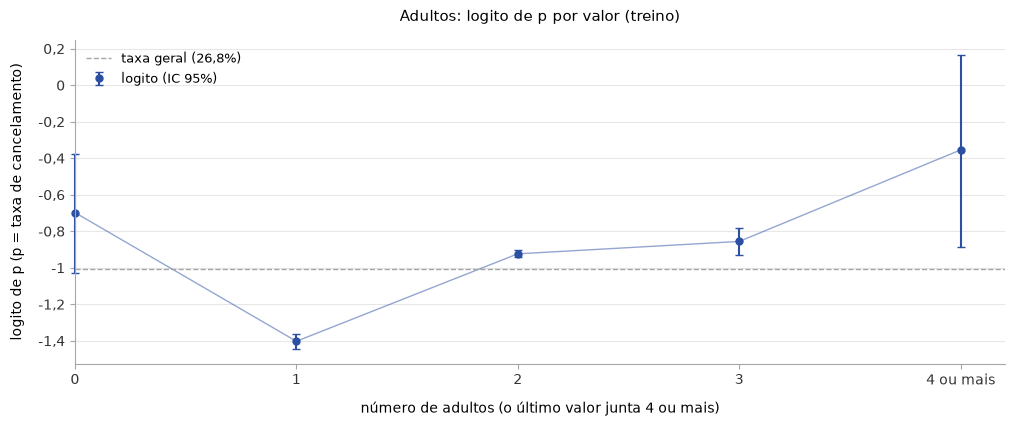

adultos,n,taxa,ic_inf,ic_sup,logito,taxa_2015,taxa_2016
0,160,0.3312,0.2630,0.4074,-0.6978,0.3333,0.3310
1,13555,0.1973,0.1907,0.2041,-1.4028,0.1640,0.2108
2,50152,0.2842,0.2802,0.2881,-0.9238,0.2722,0.2887
3,3532,0.2981,0.2833,0.3134,-0.8559,0.1542,0.3187
4 ou mais,56,0.4107,0.2917,0.5412,-0.3545,0.7500,0.1562


In [26]:
# adultos: logito de p por valor (treino); o último valor junta 4 ou mais
limites_adultos = [-1, 0, 1, 2, 3, np.inf]
rotulos_adultos = ['0', '1', '2', '3', '4 ou mais']
tabela_adultos = logito_por_faixa(treino, 'adults', limites=limites_adultos)
tabela_adultos.index = rotulos_adultos

fig, ax = plt.subplots(figsize=(12, 4.2))
grafico_logito(tabela_adultos, titulo='Adultos: logito de p por valor (treino)',
               rotulo_x='número de adultos (o último valor junta 4 ou mais)', taxa_geral=taxa_treino,
               posicao=range(len(rotulos_adultos)), ax=ax)
ax.set_xticks(range(len(rotulos_adultos)), rotulos_adultos)
plt.show()

faixa_adultos = pd.cut(treino['adults'], limites_adultos, labels=rotulos_adultos)
por_ano = treino.groupby([faixa_adultos, 'arrival_date_year'], observed=True)['is_canceled'].mean().unstack()
tabela_adultos[['taxa_2015', 'taxa_2016']] = por_ano.reindex(rotulos_adultos)[[2015, 2016]].to_numpy()
tabela_adultos[['n', 'taxa', 'ic_inf', 'ic_sup', 'logito', 'taxa_2015', 'taxa_2016']].rename_axis('adultos').round(4)

**Leitura.**

- **Um adulto cancela bem menos:** 19,7%, contra 28,4% com dois e 29,8% com três.
- **Os extremos têm poucas reservas e intervalos largos:** sem adulto, 160 reservas (33,1%); 4 ou mais, 56 (41,1%).
- **Não é linear no logito:** de 1 para 2 adultos, o logito sobe 0,48; de 2 para 3, 0,07. **Entra em faixas.**

#### Valores fora do comum

As reservas sem adulto e as com 5 adultos ou mais.

In [27]:
# adultos: valores raros, conferidos antes da árvore (treino)
casos = {
    'sem adulto (só crianças ou bebês)': treino['adults'] == 0,
    '5 adultos ou mais': treino['adults'] >= 5,
}
pd.DataFrame({nome: {
    'reservas': int(caso.sum()),
    'taxa': treino.loc[caso, 'is_canceled'].mean(),
    'pct_tipo_group': (treino.loc[caso, 'customer_type'] == 'Group').mean(),
    'pct_resort_2015': ((treino.loc[caso, 'hotel'] == 'Resort Hotel') & (treino.loc[caso, 'arrival_date_year'] == 2015)).mean(),
    'maior_valor': treino.loc[caso, 'adults'].max(),
} for nome, caso in casos.items()}).T.rename_axis('caso').round(4)

caso,reservas,taxa,pct_tipo_group,pct_resort_2015,maior_valor
sem adulto (só crianças ou bebês),160,0.3312,0.0062,0,0
5 adultos ou mais,16,1,1,1,55


**Leitura.**

- **Sem adulto: 160 reservas, com 33,1% de cancelamento.** O notebook 01 (seção 4.3) propõe mantê-las. São 0,2% do treino, menos que o mínimo de uma faixa: a árvore vai juntá-las a um valor vizinho, e a comparação abaixo confere se esse é o melhor lado.
- **5 adultos ou mais: 16 reservas, todas canceladas**, todas do tipo Group, no resort, em 2015, com até 55 adultos. Parecem blocos de grupo lançados como uma reserva só. Em qualquer agrupamento, caem no último nível: **ficam.**

#### Onde cortar: árvore de decisão

A mesma árvore das seções anteriores, com as mesmas regras de parada.

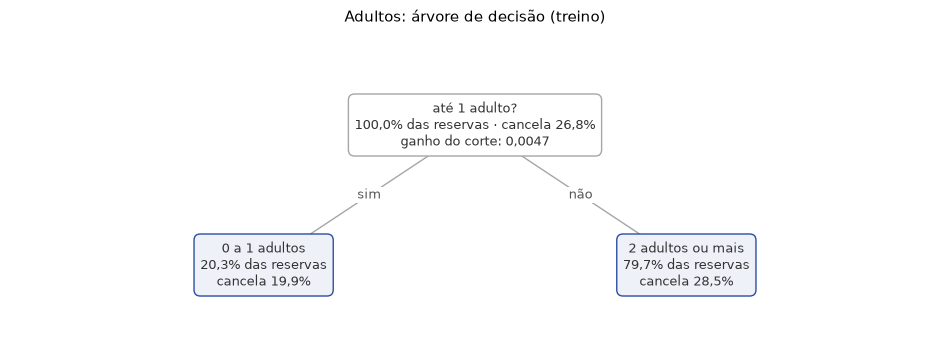

A árvore para em 2 faixas: o próximo corte (2 adultos) teria ganho de 0,00004, abaixo do mínimo de 0,0005.


In [28]:
# adultos: a árvore que as regras de parada produzem (treino)
passos_adultos = cortes_por_ganho(treino, 'adults')
n_faixas_adultos = int((passos_adultos['aceito'] == 'sim').sum()) + 1
desenhar_arvore(treino, 'adults', n_faixas=n_faixas_adultos, unidade='adultos', ultima='ou mais',
                titulo='Adultos: árvore de decisão (treino)')

# por que a árvore para aqui
parada = passos_adultos[passos_adultos['aceito'] == 'não'].iloc[0]
ganho_parada = f"{parada['ganho']:.5f}".replace('.', ',')   # 5 casas: com 4, o ganho sairia como zero
print(f"A árvore para em {n_faixas_adultos} faixas: o próximo corte ({parada['corte_novo']} adultos) teria ganho de "
      f"{ganho_parada}, abaixo do mínimo de 0,0005.")

**Leitura.**

- **A árvore faz um corte só: até 1 adulto × 2 ou mais** (ganho de 0,0047).
- **O corte seguinte, em 2 adultos, traria 0,00004**, muito abaixo do mínimo.
- **As 160 reservas sem adulto ficam com as de 1 adulto.** A árvore só junta valores vizinhos, e o zero não forma faixa própria.

#### O corte em 2015 e em 2016

Como nas seções anteriores: a taxa de cada faixa em cada ano do treino.

In [29]:
# adultos: o corte da árvore vale em 2015 e em 2016? (só o treino)
cortes_adultos, conferencia_adultos, saidas_adultos = conferir_cortes_por_periodo(treino, 'adults', passos_adultos)
display(conferencia_adultos.round(4))
print('Cortes que ficam:', cortes_adultos)

rodada,faixa,taxa_2015,taxa_2016,mesma_ordem
1,0–1,0.1647,0.2126,
1,mais de 1,0.2694,0.2909,sim


Cortes que ficam: [1]


**Leitura.**

- **O corte vale nos dois anos:** até 1 adulto cancela 16,5% em 2015 e 21,3% em 2016, contra 26,9% e 29,1% com 2 ou mais. **Fica.**

#### Comparação das opções

Cada opção vira um modelo só com a variável. Entram a árvore, a árvore com o corte seguinte, todos os valores separados, a variável como número e o modelo sem nenhuma variável. Entra também "1 adulto × os demais", que põe as reservas sem adulto junto das com 2 adultos ou mais.

Quando o AIC e o BIC discordam, vale o BIC, como nas noites: ele pune mais cada coeficiente e favorece a opção mais simples. A exceção é quando o BIC não separa as opções (diferença de até 2 pontos): aí vale o AIC.

In [30]:
# adultos: a árvore comparada com as outras opções (treino)
comparar_cortes(treino, 'adults', {
    'árvore: até 1 / 2 ou mais': [-1, 1, np.inf],
    'árvore com o próximo corte: até 1 / 2 / 3 ou mais': [-1, 1, 2, np.inf],
    'por valor: 0 / 1 / 2 / 3 / 4 ou mais': [-1, 0, 1, 2, 3, np.inf],
}, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'adultos como número': 'is_canceled ~ adults',
    'sozinho: 1 adulto / os demais (0, 2 ou mais)': 'is_canceled ~ I(adults == 1)',
})

opcao,faixas,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,menor_faixa,taxa_por_faixa
por valor: 0 / 1 / 2 / 3 / 4 ou mais,5,4,77925.3000,0,77970.9000,24.6000,0.0008,"33,1% / 19,7% / 28,4% / 29,8% / 41,1%"
"sozinho: 1 adulto / os demais (0, 2 ou mais)",,1,77928.1000,2.8000,77946.3000,0,,
árvore com o próximo corte: até 1 / 2 / 3 ou mais,3,2,77940.1000,14.8000,77967.5000,21.1000,0.0532,"19,9% / 28,4% / 30,0%"
árvore: até 1 / 2 ou mais,2,1,77942.1000,16.8000,77960.4000,14,0.2033,"19,9% / 28,5%"
adultos como número,,1,78002.6000,77.2000,78020.8000,74.5000,,
sem nenhuma variável,,0,78375.6000,450.2000,78384.7000,438.4000,,


**Leitura.**

- **"1 adulto × os demais" é a melhor opção pelo BIC.** A árvore fica 14,0 pontos atrás: as reservas sem adulto cancelam 33,1%, perto das de 2 adultos (28,4%) e longe das de 1 (19,7%).
- **Separar todos os valores ganha pelo AIC por 2,8 pontos**, mas usa 3 coeficientes a mais e fica 24,6 pontos atrás pelo BIC. Vale o BIC.
- **Adultos como número fica 74,5 pontos de BIC atrás.**
- **Proposta: sozinho (1 adulto) × outros (0 ou 2 ou mais adultos).** A ordem nos dois anos é conferida abaixo.

#### Níveis finais

Taxa de cada nível no treino, com o intervalo de confiança, e em cada ano do treino. A referência vem primeiro.

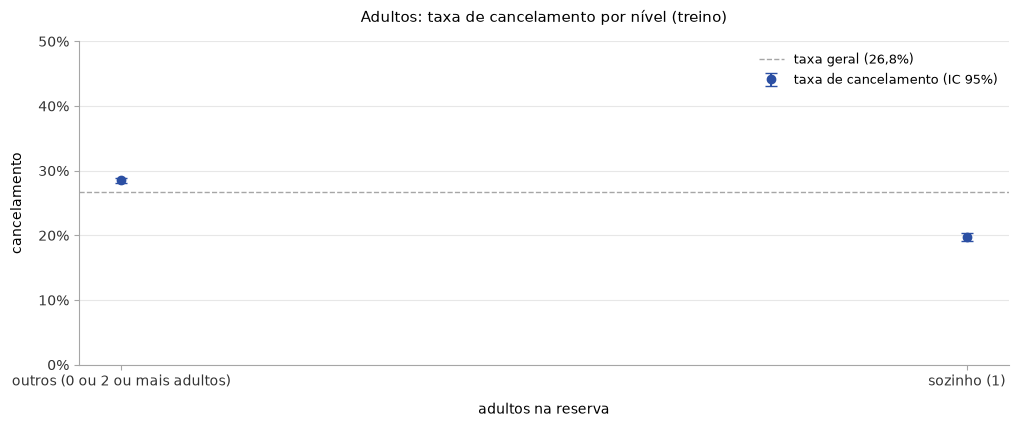

adultos,n,pct_base,taxa,ic_inf,ic_sup,taxa_2015,taxa_2016
outros (0 ou 2 ou mais adultos),53900,0.7991,0.2854,0.2816,0.2892,0.2694,0.2911
sozinho (1),13555,0.2009,0.1973,0.1907,0.2041,0.1640,0.2108


In [31]:
# adultos: níveis escolhidos; a referência é o primeiro nível
niveis_adultos = pd.Categorical(np.where(treino['adults'] == 1, 'sozinho (1)', 'outros (0 ou 2 ou mais adultos)'),
                                categories=['outros (0 ou 2 ou mais adultos)', 'sozinho (1)'])
com_nivel = treino.assign(adultos=niveis_adultos)
tabela = taxa_por_nivel(com_nivel, 'adultos')[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']]
por_ano = com_nivel.groupby(['adultos', 'arrival_date_year'], observed=True)['is_canceled'].mean().unstack()
tabela[['taxa_2015', 'taxa_2016']] = por_ano[[2015, 2016]].to_numpy()

ax = grafico_taxa_por_nivel(tabela, taxa_geral=taxa_treino, titulo='Adultos: taxa de cancelamento por nível (treino)')
ax.figure.set_size_inches(12, 4.2)
ax.set_ylim(0, 0.5)
ax.set_xlabel('adultos na reserva')
plt.show()
tabela.round(4)

**Leitura.**

- **Sozinho cancela 19,7%, contra 28,5% nos outros.** Os intervalos não se tocam.
- **A ordem se mantém nos dois anos:** 16,4% e 26,9% em 2015; 21,1% e 29,1% em 2016.
- **Referência: outros**, o nível maior (79,9% do treino).
- **Para a apresentação:** "hóspede sozinho" × "demais reservas".

### 3.5 Crianças

#### Logito de p por valor

Um ponto por número de crianças; o último junta 3 ou mais. A tabela traz também a taxa em cada ano do treino.

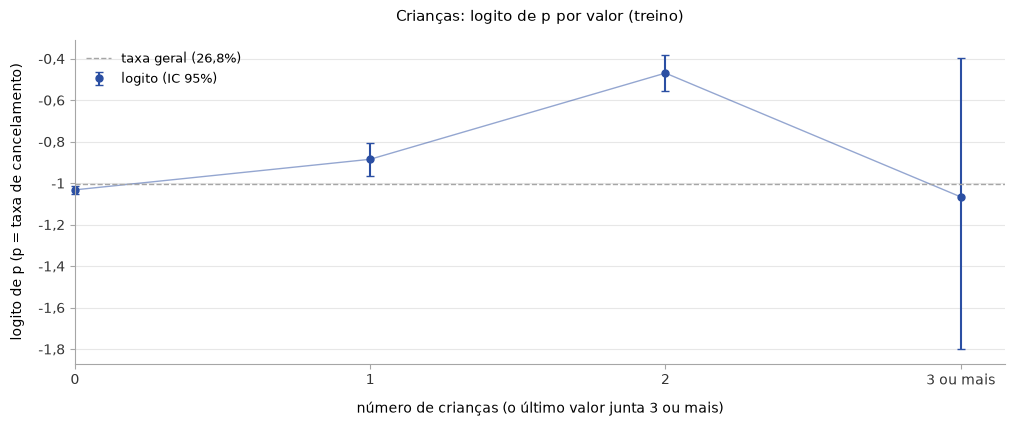

criancas,n,taxa,ic_inf,ic_sup,logito,taxa_2015,taxa_2016
0,62449,0.2626,0.2592,0.2661,-1.0325,0.2484,0.2680
1,2842,0.2920,0.2756,0.3090,-0.8851,0.1635,0.3176
2,2124,0.3847,0.3642,0.4055,-0.4696,0.2719,0.4127
3 ou mais,40,0.2500,0.1419,0.4019,-1.0664,0.3333,0.2353


In [32]:
# crianças: logito de p por valor (treino); o último valor junta 3 ou mais
limites_criancas = [-1, 0, 1, 2, np.inf]
rotulos_criancas = ['0', '1', '2', '3 ou mais']
tabela_criancas = logito_por_faixa(treino, 'children', limites=limites_criancas)
tabela_criancas.index = rotulos_criancas

fig, ax = plt.subplots(figsize=(12, 4.2))
grafico_logito(tabela_criancas, titulo='Crianças: logito de p por valor (treino)',
               rotulo_x='número de crianças (o último valor junta 3 ou mais)', taxa_geral=taxa_treino,
               posicao=range(len(rotulos_criancas)), ax=ax)
ax.set_xticks(range(len(rotulos_criancas)), rotulos_criancas)
plt.show()

faixa_criancas = pd.cut(treino['children'], limites_criancas, labels=rotulos_criancas)
por_ano = treino.groupby([faixa_criancas, 'arrival_date_year'], observed=True)['is_canceled'].mean().unstack()
tabela_criancas[['taxa_2015', 'taxa_2016']] = por_ano.reindex(rotulos_criancas)[[2015, 2016]].to_numpy()
tabela_criancas[['n', 'taxa', 'ic_inf', 'ic_sup', 'logito', 'taxa_2015', 'taxa_2016']].rename_axis('criancas').round(4)

**Leitura.**

- **O cancelamento sobe até 2 crianças:** 26,3% sem criança, 29,2% com uma e 38,5% com duas. Com 3 ou mais, são só 40 reservas (25,0%), com intervalo largo.
- **Não é linear no logito:** de 0 para 1 criança, o logito sobe 0,15; de 1 para 2, 0,42; com 3 ou mais, volta a cair. **Entra em faixas.**
- **Em 2015, uma criança cancela menos que nenhuma** (16,4% contra 24,8%); em 2016, mais (31,8% contra 26,8%). A árvore e a conferência por ano, abaixo, dizem se vale separar 0 de 1.

#### Valores fora do comum

As reservas com 3 crianças ou mais.

In [33]:
# crianças: reservas com 3 ou mais (treino)
treino[treino['children'] >= 3].groupby('children')['is_canceled'].agg(reservas='size', taxa='mean').round(4)

children,reservas,taxa
3,39,0.2308
10,1,1


**Leitura.**

- **40 reservas com 3 crianças ou mais**, quase todas com 3. Uma tem 10 crianças, provável erro de digitação.
- **Em qualquer agrupamento, caem no último nível:** **ficam.**

#### Onde cortar: árvore de decisão

A mesma árvore das seções anteriores, com as mesmas regras de parada.

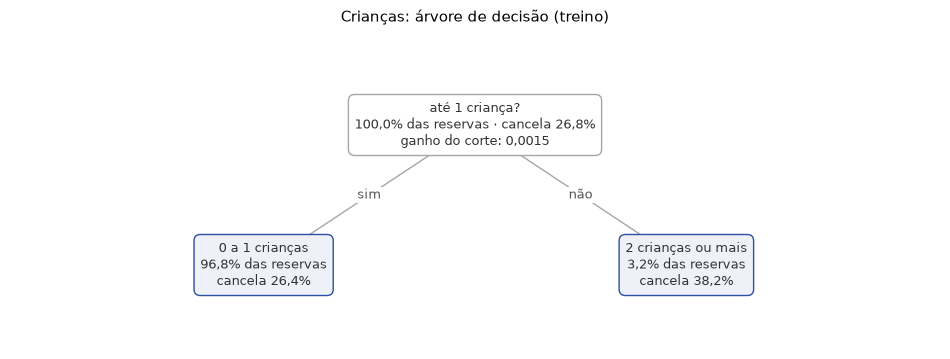

A árvore para em 2 faixas: o próximo corte (separar 0 de 1 criança) teria ganho de 0,00013, abaixo do mínimo de 0,0005.


In [34]:
# crianças: a árvore que as regras de parada produzem (treino)
passos_criancas = cortes_por_ganho(treino, 'children')
n_faixas_criancas = int((passos_criancas['aceito'] == 'sim').sum()) + 1
desenhar_arvore(treino, 'children', n_faixas=n_faixas_criancas, unidade='crianças', ultima='ou mais',
                titulo='Crianças: árvore de decisão (treino)')

# por que a árvore para aqui
parada = passos_criancas[passos_criancas['aceito'] == 'não'].iloc[0]
ganho_parada = f"{parada['ganho']:.5f}".replace('.', ',')   # 5 casas: com 4, o ganho sairia como 0,0001
print(f"A árvore para em {n_faixas_criancas} faixas: o próximo corte (separar 0 de 1 criança) teria "
      f"ganho de {ganho_parada}, abaixo do mínimo de 0,0005.")

**Leitura.**

- **A árvore faz um corte só: até 1 criança × 2 ou mais** (ganho de 0,0015).
- **Separar 0 de 1 criança traria 0,00013**, abaixo do mínimo. A árvore não aceita esse corte.

#### O corte em 2015 e em 2016

Como nas seções anteriores: a taxa de cada faixa em cada ano do treino.

In [35]:
# crianças: o corte da árvore vale em 2015 e em 2016? (só o treino)
cortes_criancas, conferencia_criancas, saidas_criancas = conferir_cortes_por_periodo(treino, 'children', passos_criancas)
display(conferencia_criancas.round(4))
print('Cortes que ficam:', cortes_criancas)

rodada,faixa,taxa_2015,taxa_2016,mesma_ordem
1,0–1,0.2462,0.2705,
1,mais de 1,0.2727,0.4092,sim


Cortes que ficam: [1]


**Leitura.**

- **O corte vale nos dois anos:** até 1 criança cancela 24,6% em 2015 e 27,1% em 2016, contra 27,3% e 40,9% com 2 ou mais. **Fica.**
- **Em 2015, a diferença é pequena** (2,7 pontos); em 2016, chega a 13,9 pontos.

#### Comparação das opções

As mesmas opções das seções anteriores: a árvore, a árvore com o corte seguinte, "com criança × sem criança", a variável como número e o modelo sem nenhuma variável.

In [36]:
# crianças: a árvore comparada com as outras opções (treino)
comparar_cortes(treino, 'children', {
    'árvore: até 1 / 2 ou mais': [-1, 1, np.inf],
    'árvore com o próximo corte: 0 / 1 / 2 ou mais': [-1, 0, 1, np.inf],
    'com criança / sem criança': [-1, 0, np.inf],
}, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'crianças como número': 'is_canceled ~ children',
})

opcao,faixas,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,menor_faixa,taxa_por_faixa
árvore com o próximo corte: 0 / 1 / 2 ou mais,3,2,78228.5000,0,78255.9000,1.9000,0.0321,"26,3% / 29,2% / 38,2%"
crianças como número,,1,78235.7000,7.2000,78254,0,,
árvore: até 1 / 2 ou mais,2,1,78238.4000,9.9000,78256.6000,2.7000,0.0321,"26,4% / 38,2%"
com criança / sem criança,2,1,78271.4000,42.9000,78289.6000,35.7000,0.0742,"26,3% / 33,1%"
sem nenhuma variável,,0,78375.6000,147.1000,78384.7000,130.7000,,


**Leitura.**

- **Pelo BIC, crianças como número é a melhor opção;** os três níveis (0 / 1 / 2 ou mais) ficam 1,9 ponto atrás, e a árvore, 2,7.
- **O número não entra:** as crianças não são lineares no logito (logito por valor, acima).
- **Os três níveis não entram:** a árvore não aceita o corte entre 0 e 1 criança, e ele inverte entre 2015 e 2016.
- **"Com criança × sem criança" fica 35,7 pontos de BIC atrás:** junta 1 criança (29,2%) com 2 ou mais (38,2%).
- **Proposta: até 1 criança × 2 ou mais.**

#### Níveis finais

Taxa de cada nível no treino, com o intervalo de confiança, e em cada ano do treino.

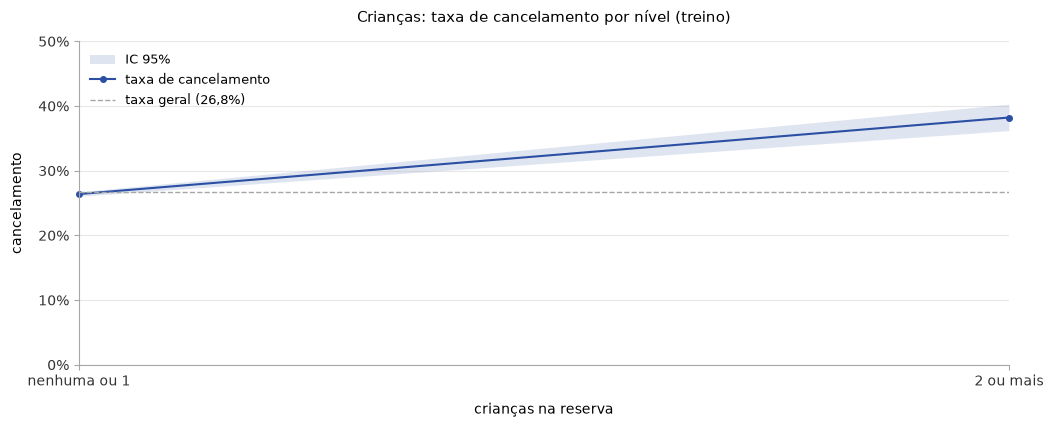

children,n,pct_base,taxa,ic_inf,ic_sup,taxa_2015,taxa_2016
nenhuma ou 1,65291,0.9679,0.2639,0.2605,0.2673,0.2462,0.2705
2 ou mais,2164,0.0321,0.3822,0.3619,0.4028,0.2727,0.4092


In [37]:
# limites para o pd.cut (cada faixa inclui o limite da direita; o -1 serve para incluir o 0):
#   (-1, 1] = nenhuma ou 1 criança | (1, inf) = 2 ou mais
faixas_criancas = [-1, 1, np.inf]
rotulos_faixas_criancas = ['nenhuma ou 1', '2 ou mais']
conferir_faixas('children', faixas_criancas, rotulos_faixas_criancas,
                'Crianças: taxa de cancelamento por nível (treino)', 'crianças na reserva')

**Leitura.**

- **Duas crianças ou mais cancelam 38,2%, contra 26,4% com nenhuma ou uma.** Os intervalos não se tocam.
- **A ordem se mantém nos dois anos:** 24,6% e 27,3% em 2015; 27,1% e 40,9% em 2016.
- **Referência: nenhuma ou 1 criança**, o nível maior (96,8% do treino).
- **Para a apresentação:** "famílias com duas crianças ou mais".

### 3.6 Bebês

#### Logito de p por valor

Um ponto por número de bebês; o último junta 2 ou mais. A tabela traz também a taxa em cada ano do treino.

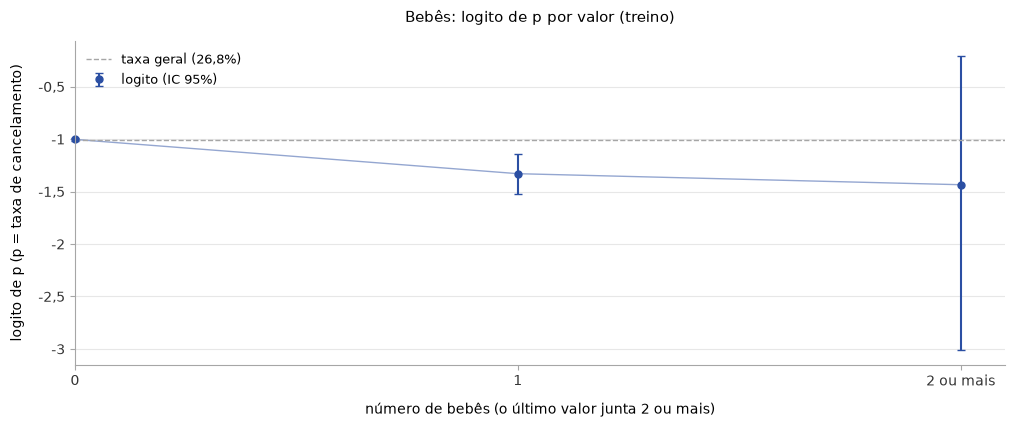

bebes,n,taxa,ic_inf,ic_sup,taxa_2015,taxa_2016
0,66801,0.2683,0.2649,0.2716,0.2474,0.2759
1,642,0.2087,0.1791,0.2418,0.1971,0.2143
2 ou mais,12,0.1667,0.0470,0.4480,0,0.2222


In [38]:
# bebês: logito de p por valor (treino); o último valor junta 2 ou mais
limites_bebes = [-1, 0, 1, np.inf]
rotulos_bebes = ['0', '1', '2 ou mais']
tabela_bebes = logito_por_faixa(treino, 'babies', limites=limites_bebes)
tabela_bebes.index = rotulos_bebes

fig, ax = plt.subplots(figsize=(12, 4.2))
grafico_logito(tabela_bebes, titulo='Bebês: logito de p por valor (treino)',
               rotulo_x='número de bebês (o último valor junta 2 ou mais)', taxa_geral=taxa_treino,
               posicao=range(len(rotulos_bebes)), ax=ax)
ax.set_xticks(range(len(rotulos_bebes)), rotulos_bebes)
plt.show()

faixa_bebes = pd.cut(treino['babies'], limites_bebes, labels=rotulos_bebes)
por_ano = treino.groupby([faixa_bebes, 'arrival_date_year'], observed=True)['is_canceled'].mean().unstack()
tabela_bebes[['taxa_2015', 'taxa_2016']] = por_ano.reindex(rotulos_bebes)[[2015, 2016]].to_numpy()
tabela_bebes[['n', 'taxa', 'ic_inf', 'ic_sup', 'taxa_2015', 'taxa_2016']].rename_axis('bebes').round(4)

**Leitura.**

- **Com bebê, a reserva cancela menos:** 20,9% com 1 bebê (IC de 17,9% a 24,2%), contra 26,8% sem bebê. Com 2 ou mais, são só 12 reservas.
- **A diferença aparece nos dois anos:** com 1 bebê, 19,7% em 2015 e 21,4% em 2016, contra 24,7% e 27,6% sem bebê.
- **São poucas reservas:** 654 com bebê no treino, cerca de 1%. Com um nível só bem estimado, a pergunta é se o corte "sem × com bebê" vale uma variável. A árvore responde abaixo.

#### Valores fora do comum

As reservas com mais de 2 bebês.

In [39]:
# bebês: as reservas com mais de 2 bebês (treino)
treino.loc[treino['babies'] > 2, ['adults', 'children', 'babies', 'hotel', 'market_segment', 'adr', 'is_canceled']]

linha,adults,children,babies,hotel,market_segment,adr,is_canceled
46619,2,0,10,City Hotel,Online TA,84.4500,0
78656,1,0,9,City Hotel,Corporate,95,0


**Leitura.**

- **Duas reservas, provável erro de digitação:** uma com 9 bebês e 1 adulto, corporativa; outra com 10 bebês e 2 adultos, da agência online. Nenhuma foi cancelada.
- **Não mudam a árvore:** em qualquer corte, caem do lado "com bebê". Ficam.

#### Onde cortar: árvore de decisão

A mesma árvore da antecedência e das noites, com as mesmas regras de parada. A tabela mostra o melhor corte que ela testou.

In [40]:
# bebês: os passos da árvore de decisão (treino)
passos_bebes = cortes_por_ganho(treino, 'babies')
display(passos_bebes)

primeiro = passos_bebes.iloc[0]
ganho_bebes = f"{primeiro['ganho']:.5f}".replace('.', ',')   # 5 casas: com 4, o ganho sairia como 0,0001
print(f"Cortes aceitos: {(passos_bebes['aceito'] == 'sim').sum()}. O melhor corte (sem × com bebê) teria ganho de "
      f"{ganho_bebes}, abaixo do mínimo de 0,0005.")

faixas,corte_novo,ganho,ganho_acumulado,aceito,cortes
2,0,0.0001,0.0001,não,0


Cortes aceitos: 0. O melhor corte (sem × com bebê) teria ganho de 0,00014, abaixo do mínimo de 0,0005.


**Leitura.**

- **A árvore não faz nenhum corte.** Separar "sem bebê" de "com bebê" traria ganho de 0,00014, pouco mais de um quarto do mínimo de 0,0005.
- **Pelo método, os bebês sozinhos não separam o cancelamento o bastante para virar faixas.** A comparação abaixo confere pelo AIC e pelo BIC.

#### Comparação das opções

Como nas outras variáveis: "com bebê × sem bebê", os valores separados, a variável como número e o modelo sem nenhuma variável.

In [41]:
# bebês: as opções comparadas (treino)
comparar_cortes(treino, 'babies', {
    'com bebê / sem bebê': [-1, 0, np.inf],
    'por valor: 0 / 1 / 2 ou mais': [-1, 0, 1, np.inf],
}, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'bebês como número': 'is_canceled ~ babies',
})

opcao,faixas,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,menor_faixa,taxa_por_faixa
bebês como número,,1,78364.2000,0,78382.4000,0,,
com bebê / sem bebê,2,1,78364.9000,0.8000,78383.2000,0.8000,0.0097,"26,8% / 20,8%"
por valor: 0 / 1 / 2 ou mais,3,2,78366.8000,2.6000,78394.1000,11.7000,0.0002,"26,8% / 20,9% / 16,7%"
sem nenhuma variável,,0,78375.6000,11.4000,78384.7000,2.3000,,


**Leitura.**

- **"Com bebê × sem bebê" fica só 1,5 ponto de BIC à frente do modelo sem nenhuma variável:** o BIC não separa as duas opções.
- **Bebês como número fica 0,8 ponto à frente da binária**, o que também não separa. Os valores separados ficam 11,7 pontos atrás.
- **O AIC prefere a binária ao modelo vazio por 10,6 pontos.** A regra de desempate (seção 3.4) escolhe a forma de uma variável depois que a árvore aceita um corte; aqui, a árvore não aceitou nenhum.
- **Bebês não entram como variável própria.**

#### Quem são as reservas com bebê

Reservas com e sem bebê: taxa, pedido especial, hotel, segmento direto e antecedência.

In [42]:
# bebês: perfil das reservas com e sem bebê (treino)
treino.groupby(np.where(treino['babies'] > 0, 'com bebê', 'sem bebê')).agg(
    reservas=('is_canceled', 'size'),
    taxa=('is_canceled', 'mean'),
    pct_fez_pedido=('total_of_special_requests', lambda s: (s > 0).mean()),
    pct_resort=('hotel', lambda s: (s == 'Resort Hotel').mean()),
    pct_direto=('market_segment', lambda s: (s == 'Direct').mean()),
    antecedencia_mediana=('lead_time', 'median'),
).rename_axis('grupo').round(4)

grupo,reservas,taxa,pct_fez_pedido,pct_resort,pct_direto,antecedencia_mediana
com bebê,654,0.2080,0.8471,0.6101,0.2844,38.5000
sem bebê,66801,0.2683,0.4330,0.3685,0.1147,51


**Leitura.**

- **84,7% das reservas com bebê fizeram pedido especial**, contra 43,3% das outras: provavelmente o berço. Também são mais do resort (61,0% contra 36,9%) e mais diretas (28,4% contra 11,5%).
- **A taxa menor com bebê pode vir do pedido especial**, que também separa o cancelamento (seção 3.8), e não do bebê.
- **Sozinhos, os bebês não separam o cancelamento.** A seção 3.7 testa os bebês junto com adultos e crianças, comparando reservas de composição parecida.

### 3.7 Composição da reserva

Quem viaja (adultos, crianças e bebês) é informado na reserva. A pergunta do negócio: combinar as três contagens numa variável só, a "composição da reserva", prevê melhor que usá-las separadas? E os bebês, que sozinhos não separam o cancelamento (seção 3.6), ajudam quando comparados com reservas de composição parecida?

#### As categorias

Duas versões da composição. Em cada reserva, vale a primeira categoria que se aplica:

- **versão A:** com bebê → com criança (1 ou mais) → sozinho (1 adulto) → adultos sem criança;
- **versão B:** com bebê → 2 ou mais crianças → sozinho (1 adulto) → outros. Usa os cortes das seções 3.4 e 3.5.

As reservas só com crianças, sem adulto, ficam com as crianças na versão A e em "outros" na versão B.

In [43]:
# composição da reserva: as duas versões, com a taxa no treino e em cada ano
treino = treino.assign(
    sozinho=(treino['adults'] == 1).astype(int),
    duas_criancas=(treino['children'] >= 2).astype(int),
    com_bebe=(treino['babies'] > 0).astype(int),
    composicao_a=np.select([treino['babies'] > 0, treino['children'] > 0, treino['adults'] == 1],
                           ['com bebê', 'com criança', 'sozinho'], 'adultos sem criança'),
    composicao_b=np.select([treino['babies'] > 0, treino['children'] >= 2, treino['adults'] == 1],
                           ['com bebê', '2 ou mais crianças', 'sozinho'], 'outros'),
)

def taxa_com_anos(coluna):
    tabela = taxa_por_nivel(treino, coluna)[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']]
    por_ano = treino.groupby([coluna, 'arrival_date_year'])['is_canceled'].mean().unstack()
    tabela[['taxa_2015', 'taxa_2016']] = por_ano[[2015, 2016]].to_numpy()
    return tabela

pd.concat({'versão A': taxa_com_anos('composicao_a'), 'versão B': taxa_com_anos('composicao_b')},
          names=['versão', 'categoria']).round(4)

versão,categoria,n,pct_base,taxa,ic_inf,ic_sup,taxa_2015,taxa_2016
versão A,adultos sem criança,48599,0.7205,0.2815,0.2776,0.2856,0.2740,0.2844
versão A,com bebê,654,0.0097,0.2080,0.1786,0.2407,0.1943,0.2144
versão A,com criança,4893,0.0725,0.3333,0.3203,0.3467,0.2148,0.3588
versão A,sozinho,13309,0.1973,0.1958,0.1892,0.2026,0.1637,0.2089
versão B,2 ou mais crianças,2139,0.0317,0.3810,0.3607,0.4018,0.2686,0.4082
versão B,com bebê,654,0.0097,0.2080,0.1786,0.2407,0.1943,0.2144
versão B,outros,51206,0.7591,0.2824,0.2786,0.2864,0.2705,0.2868
versão B,sozinho,13456,0.1995,0.1963,0.1897,0.2031,0.1637,0.2095


**Leitura.**

- **Versão A: "com criança" inverte entre os anos.** Cancela 21,5% em 2015, abaixo de "adultos sem criança" (27,4%), e 35,9% em 2016, acima (28,4%). É o mesmo problema da seção 3.5: uma criança não se separa de nenhuma de forma estável.
- **Versão B: "2 ou mais crianças" quase não se separa de "outros" em 2015** (26,9% contra 27,1%, 0,2 ponto abaixo) e fica bem acima em 2016 (40,8% contra 28,7%). Pela regra, a ordem se inverte. "Sozinho" e "com bebê" ficam abaixo de "outros" nos dois anos.
- **"Com bebê" tem 654 reservas**, 1,0% do treino, acima do mínimo de 0,5%.

#### Comparação: composição × variáveis separadas

Cada opção vira um modelo, comparado pelo AIC e pelo BIC. Entram as duas versões da composição; as variáveis sim ou não separadas, com e sem o bebê; a combinação "sozinho × 2 ou mais crianças", que testa se o efeito de uma depende da outra; e o modelo sem nenhuma variável.

In [44]:
# composição × variáveis separadas (treino)
comparar_cortes(treino, 'adults', {}, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'separadas: sozinho + 2 ou mais crianças': 'is_canceled ~ sozinho + duas_criancas',
    'separadas: sozinho + 2 ou mais crianças + com bebê': 'is_canceled ~ sozinho + duas_criancas + com_bebe',
    'combinação: sozinho × 2 ou mais crianças': 'is_canceled ~ sozinho * duas_criancas',
    'composição, versão A': 'is_canceled ~ C(composicao_a)',
    'composição, versão B': 'is_canceled ~ C(composicao_b)',
})[['n_coeficientes', 'AIC', 'dif_AIC', 'BIC', 'dif_BIC']]

opcao,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC
separadas: sozinho + 2 ou mais crianças + com bebê,3,77805.8000,0,77842.3000,0
"composição, versão B",3,77809.7000,3.9000,77846.2000,3.9000
separadas: sozinho + 2 ou mais crianças,2,77823.9000,18.1000,77851.3000,9
combinação: sozinho × 2 ou mais crianças,3,77824.6000,18.8000,77861.1000,18.8000
"composição, versão A",3,77844.6000,38.8000,77881.1000,38.8000
sem nenhuma variável,0,78375.6000,569.8000,78384.7000,542.4000


**Leitura.**

- **As variáveis separadas com o bebê são a melhor opção pelo AIC e pelo BIC.**
- **O bebê ajuda quando adultos e crianças estão no modelo:** sem ele, as separadas ficam 9,0 pontos de BIC atrás. Sozinhos, os bebês não separavam (seção 3.6); comparados com reservas de composição parecida, cancelam menos.
- **A combinação "sozinho × 2 ou mais crianças" não acrescenta:** fica 18,8 pontos de BIC atrás. O efeito de viajar sozinho não depende de ter crianças.
- **A composição B fica 3,9 pontos de BIC atrás**, com o mesmo número de coeficientes, e "2 ou mais crianças" inverte por pouco em 2015 (acima). Vale o BIC: a diferença passa de 2 pontos.
- **A versão A fica 38,8 pontos atrás:** "com criança" junta 1 criança com 2 ou mais.
- **Proposta: sozinho (1 adulto) e 2 ou mais crianças entram; com bebê fica como candidata.** 84,7% das reservas com bebê fizeram pedido especial (seção 3.6), e o stepwise do `05_modelo.ipynb` decide se o bebê acrescenta com o pedido especial no modelo.

#### Níveis finais

Taxa de cada variável sim ou não no treino, com o intervalo de confiança, e em cada ano do treino.

In [45]:
# as três variáveis sim ou não: taxa no treino e em cada ano
pd.concat({nome: taxa_com_anos(coluna).rename(index={0: 'não', 1: 'sim'})
           for nome, coluna in [('sozinho (1 adulto)', 'sozinho'), ('2 ou mais crianças', 'duas_criancas'),
                                ('com bebê', 'com_bebe')]},
          names=['variável', 'nível']).round(4)

variável,nível,n,pct_base,taxa,ic_inf,ic_sup,taxa_2015,taxa_2016
sozinho (1 adulto),não,53900,0.7991,0.2854,0.2816,0.2892,0.2694,0.2911
sozinho (1 adulto),sim,13555,0.2009,0.1973,0.1907,0.2041,0.1640,0.2108
2 ou mais crianças,não,65291,0.9679,0.2639,0.2605,0.2673,0.2462,0.2705
2 ou mais crianças,sim,2164,0.0321,0.3822,0.3619,0.4028,0.2727,0.4092
com bebê,não,66801,0.9903,0.2683,0.2649,0.2716,0.2474,0.2759
com bebê,sim,654,0.0097,0.2080,0.1786,0.2407,0.1943,0.2144


**Leitura.**

- **Sozinho:** 19,7% contra 28,5%. **2 ou mais crianças:** 38,2% contra 26,4%. **Com bebê:** 20,8% contra 26,8%.
- **A ordem se mantém nos dois anos nas três.**
- **Referência de cada uma: "não"**, o nível maior.
- **Para a apresentação:** "quem viaja sozinho cancela menos; famílias com duas crianças ou mais cancelam mais; reservas com bebê cancelam menos".

### 3.8 Pedidos especiais

Pedidos como cama de casal, andar alto ou berço. Podem ser feitos na reserva ou depois dela, até a chegada. O momento do score está em aberto (notebook 01, Decisões para o grupo, item 8): se o score for calculado na entrada da reserva, a variável não pode entrar.

#### Logito de p por valor

Um ponto por número de pedidos; o último junta 4 ou mais. A tabela traz também a taxa em cada ano do treino.

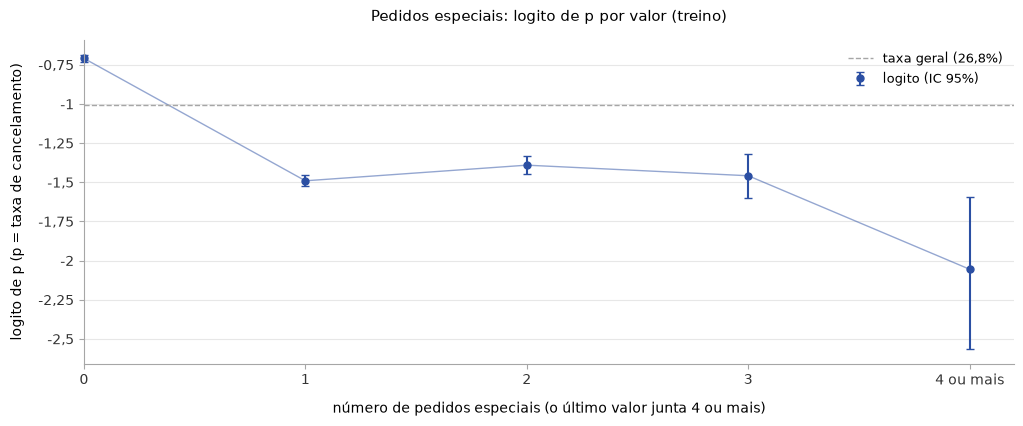

pedidos,n,taxa,ic_inf,ic_sup,logito,taxa_2015,taxa_2016
0,37975,0.3298,0.3251,0.3345,-0.7091,0.2680,0.3568
1,20278,0.1838,0.1785,0.1892,-1.4907,0.1974,0.1803
2,7740,0.1992,0.1905,0.2083,-1.3909,0.2391,0.1851
3,1300,0.1885,0.1681,0.2106,-1.4585,0.1979,0.1846
4 ou mais,162,0.1111,0.0714,0.1688,-2.0555,0.0769,0.1176


In [46]:
# pedidos especiais: logito de p por valor (treino); o último valor junta 4 ou mais
limites_pedidos = [-1, 0, 1, 2, 3, np.inf]
rotulos_pedidos = ['0', '1', '2', '3', '4 ou mais']
tabela_pedidos = logito_por_faixa(treino, 'total_of_special_requests', limites=limites_pedidos)
tabela_pedidos.index = rotulos_pedidos

fig, ax = plt.subplots(figsize=(12, 4.2))
grafico_logito(tabela_pedidos, titulo='Pedidos especiais: logito de p por valor (treino)',
               rotulo_x='número de pedidos especiais (o último valor junta 4 ou mais)', taxa_geral=taxa_treino,
               posicao=range(len(rotulos_pedidos)), ax=ax)
ax.set_xticks(range(len(rotulos_pedidos)), rotulos_pedidos)
plt.show()

faixa_pedidos = pd.cut(treino['total_of_special_requests'], limites_pedidos, labels=rotulos_pedidos)
por_ano = treino.groupby([faixa_pedidos, 'arrival_date_year'], observed=True)['is_canceled'].mean().unstack()
tabela_pedidos[['taxa_2015', 'taxa_2016']] = por_ano.reindex(rotulos_pedidos)[[2015, 2016]].to_numpy()
tabela_pedidos[['n', 'taxa', 'ic_inf', 'ic_sup', 'logito', 'taxa_2015', 'taxa_2016']].rename_axis('pedidos').round(4)

**Leitura.**

- **O que importa é fazer algum pedido.** Sem pedido, 33,0%; com 1, 2 ou 3 pedidos, entre 18,4% e 19,9%. Com 4 ou mais, 11,1%, mas são só 162 reservas.
- **Não é linear no logito:** de 0 para 1 pedido, o logito cai 0,78; de 1 a 3, quase não muda. **Entra em faixas.**
- **Os valores vão de 0 a 5,** sem nada fora do comum.

#### Onde cortar: árvore de decisão

A mesma árvore das seções anteriores, com as mesmas regras de parada.

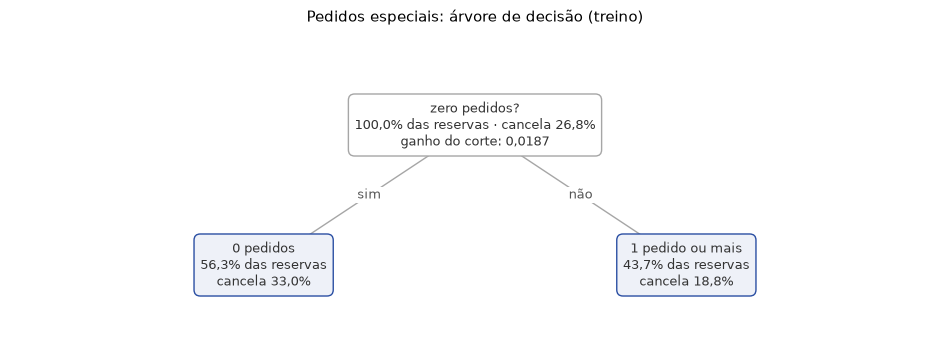

A árvore para em 2 faixas: o próximo corte (separar 1 pedido de 2 ou mais) teria ganho de 0,00007, abaixo do mínimo de 0,0005.


In [47]:
# pedidos especiais: a árvore que as regras de parada produzem (treino)
passos_pedidos = cortes_por_ganho(treino, 'total_of_special_requests')
n_faixas_pedidos = int((passos_pedidos['aceito'] == 'sim').sum()) + 1
desenhar_arvore(treino, 'total_of_special_requests', n_faixas=n_faixas_pedidos, unidade='pedidos', ultima='ou mais',
                titulo='Pedidos especiais: árvore de decisão (treino)')

# por que a árvore para aqui
parada = passos_pedidos[passos_pedidos['aceito'] == 'não'].iloc[0]
ganho_parada = f"{parada['ganho']:.5f}".replace('.', ',')   # 5 casas: com 4, o ganho sairia como 0,0001
print(f"A árvore para em {n_faixas_pedidos} faixas: o próximo corte (separar 1 pedido de 2 ou mais) teria ganho de "
      f"{ganho_parada}, abaixo do mínimo de 0,0005.")

**Leitura.**

- **A árvore faz um corte só: nenhum pedido × 1 ou mais**, com ganho de 0,0187, o maior de todas as contagens.
- **Separar 1 pedido de 2 ou mais traria 0,00007**, muito abaixo do mínimo.

#### O corte em 2015 e em 2016

Como nas seções anteriores: a taxa de cada faixa em cada ano do treino.

In [48]:
# pedidos especiais: o corte da árvore vale em 2015 e em 2016? (só o treino)
cortes_pedidos, conferencia_pedidos, saidas_pedidos = conferir_cortes_por_periodo(treino, 'total_of_special_requests',
                                                                                  passos_pedidos)
display(conferencia_pedidos.round(4))
print('Cortes que ficam:', cortes_pedidos)

rodada,faixa,taxa_2015,taxa_2016,mesma_ordem
1,0,0.2680,0.3568,
1,mais de 0,0.2097,0.1813,sim


Cortes que ficam: [0]


**Leitura.**

- **O corte vale nos dois anos:** sem pedido, 26,8% em 2015 e 35,7% em 2016; com pedido, 21,0% e 18,1%. **Fica.**
- **A diferença cresce de um ano para o outro:** 5,8 pontos em 2015 e 17,6 em 2016.

#### Comparação das opções

A árvore, a árvore com o corte seguinte, todos os valores separados, a variável como número, o logaritmo e o modelo sem nenhuma variável.

In [49]:
# pedidos especiais: a árvore comparada com as outras opções (treino)
comparar_cortes(treino, 'total_of_special_requests', {
    'árvore: 0 / 1 ou mais': [-1, 0, np.inf],
    'árvore com o próximo corte: 0 / 1 / 2 ou mais': [-1, 0, 1, np.inf],
    'por valor: 0 / 1 / 2 / 3 ou mais': [-1, 0, 1, 2, np.inf],
}, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'pedidos como número': 'is_canceled ~ total_of_special_requests',
    'logaritmo dos pedidos': 'is_canceled ~ np.log1p(total_of_special_requests)',
})

opcao,faixas,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,menor_faixa,taxa_por_faixa
por valor: 0 / 1 / 2 / 3 ou mais,4,3,76619.6000,0,76656.1000,13,0.0217,"33,0% / 18,4% / 19,9% / 18,0%"
árvore com o próximo corte: 0 / 1 / 2 ou mais,3,2,76620.5000,1,76647.9000,4.8000,0.1364,"33,0% / 18,4% / 19,6%"
árvore: 0 / 1 ou mais,2,1,76624.8000,5.3000,76643.1000,0,0.4370,"33,0% / 18,8%"
logaritmo dos pedidos,,1,76826.7000,207.1000,76844.9000,201.9000,,
pedidos como número,,1,77044.4000,424.9000,77062.7000,419.6000,,
sem nenhuma variável,,0,78375.6000,1756,78384.7000,1741.6000,,


**Leitura.**

- **A árvore (nenhum pedido × 1 ou mais) é a melhor pelo BIC.** Separar os valores ganha pelo AIC por 5,3 pontos, com 2 coeficientes a mais, e fica 13,0 pontos atrás pelo BIC. Vale o BIC.
- **Pedidos como número fica 419,6 pontos de BIC atrás**, e o logaritmo, 201,9.
- **Proposta: fez pedido × nenhum, como candidata:** depende do momento do score. O `05_modelo.ipynb` compara o modelo com e sem o pedido especial.

#### Níveis finais

Taxa de cada nível no treino, com o intervalo de confiança, e em cada ano do treino.

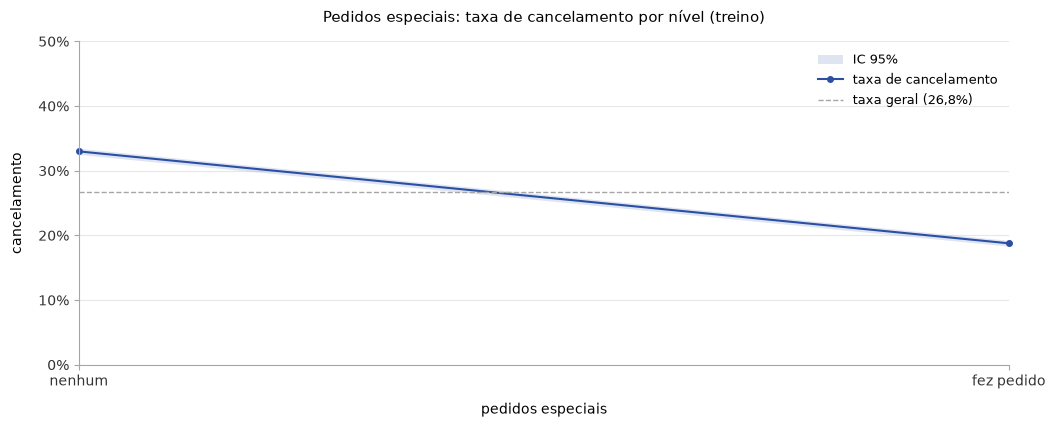

total_of_special_requests,n,pct_base,taxa,ic_inf,ic_sup,taxa_2015,taxa_2016
nenhum,37975,0.5630,0.3298,0.3251,0.3345,0.2680,0.3568
fez pedido,29480,0.4370,0.1877,0.1832,0.1922,0.2097,0.1813


In [50]:
# limites para o pd.cut (cada faixa inclui o limite da direita; o -1 serve para incluir o 0):
#   (-1, 0] = nenhum pedido | (0, inf) = 1 ou mais
conferir_faixas('total_of_special_requests', [-1, 0, np.inf], ['nenhum', 'fez pedido'],
                'Pedidos especiais: taxa de cancelamento por nível (treino)', 'pedidos especiais')

**Leitura.**

- **Quem faz algum pedido cancela 18,8%, contra 33,0% de quem não faz.** Os intervalos não se tocam.
- **A ordem se mantém nos dois anos:** 26,8% e 21,0% em 2015; 35,7% e 18,1% em 2016.
- **Referência: nenhum pedido**, o nível maior (56,3% do treino).
- **Para a apresentação:** "quem faz um pedido especial, como berço ou andar alto, cancela bem menos".

### 3.9 Histórico do cliente

Três contagens sobre o passado do cliente: reservas anteriores que ele manteve, dias em lista de espera e cancelamentos anteriores. Cada uma passa pelo mesmo método das seções anteriores.

#### Reservas anteriores mantidas: logito de p por valor

Um ponto por número de reservas anteriores mantidas; o último junta 3 ou mais. A tabela traz também a taxa em cada ano do treino.

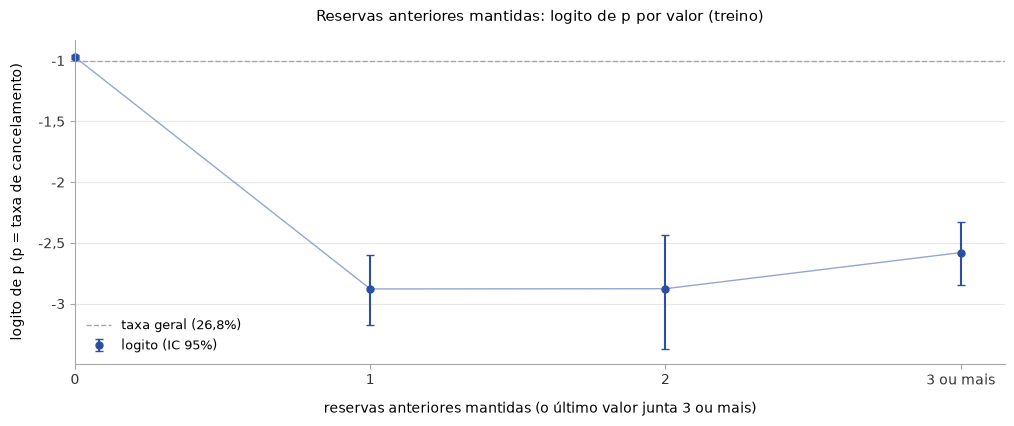

reservas_anteriores,n,taxa,ic_inf,ic_sup,logito,taxa_2015,taxa_2016
0,65308,0.2745,0.2711,0.2780,-0.9718,0.2499,0.2838
1,929,0.0527,0.0401,0.0690,-2.8785,0.0409,0.0554
2,346,0.0520,0.0332,0.0807,-2.8768,0.1167,0.0385
3 ou mais,872,0.0700,0.0548,0.0888,-2.5798,0.0789,0.0691


In [51]:
# reservas anteriores mantidas: logito de p por valor (treino); o último valor junta 3 ou mais
def logito_por_valor(coluna, limites, rotulos, titulo, rotulo_x, nome_indice):
    tabela = logito_por_faixa(treino, coluna, limites=limites)
    tabela.index = rotulos
    fig, ax = plt.subplots(figsize=(12, 4.2))
    grafico_logito(tabela, titulo=titulo, rotulo_x=rotulo_x, taxa_geral=taxa_treino,
                   posicao=range(len(rotulos)), ax=ax)
    ax.set_xticks(range(len(rotulos)), rotulos)
    plt.show()
    faixa = pd.cut(treino[coluna], limites, labels=rotulos)
    por_ano = treino.groupby([faixa, 'arrival_date_year'], observed=True)['is_canceled'].mean().unstack()
    tabela[['taxa_2015', 'taxa_2016']] = por_ano.reindex(rotulos)[[2015, 2016]].to_numpy()
    return tabela[['n', 'taxa', 'ic_inf', 'ic_sup', 'logito', 'taxa_2015', 'taxa_2016']].rename_axis(nome_indice).round(4)

logito_por_valor('previous_bookings_not_canceled', [-1, 0, 1, 2, np.inf], ['0', '1', '2', '3 ou mais'],
                 'Reservas anteriores mantidas: logito de p por valor (treino)',
                 'reservas anteriores mantidas (o último valor junta 3 ou mais)', 'reservas_anteriores')

**Leitura.**

- **Um degrau só:** quem nunca veio cancela 27,5%; quem já veio uma ou mais vezes, entre 5,2% e 7,0%.
- **Não é linear no logito:** o logito cai 1,9 de 0 para 1 e quase não muda depois. **Entra em faixas.**
- **A cauda chega a 58 reservas anteriores**, de clientes frequentes. Em qualquer agrupamento, cai no último nível.

#### Reservas anteriores mantidas: árvore de decisão

A mesma árvore das seções anteriores, com as mesmas regras de parada.

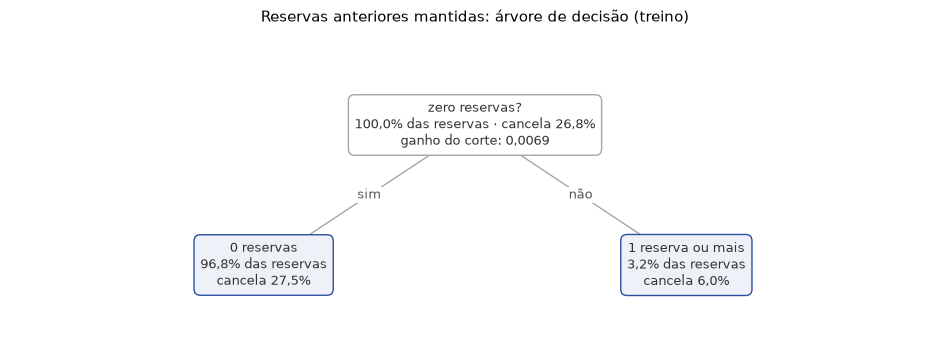

A árvore para em 2 faixas: o próximo corte (3 reservas) teria ganho de 0,00004, abaixo do mínimo de 0,0005.


In [52]:
# reservas anteriores mantidas: a árvore que as regras de parada produzem (treino)
passos_anteriores = cortes_por_ganho(treino, 'previous_bookings_not_canceled')
n_faixas_anteriores = int((passos_anteriores['aceito'] == 'sim').sum()) + 1
desenhar_arvore(treino, 'previous_bookings_not_canceled', n_faixas=n_faixas_anteriores, unidade='reservas',
                ultima='ou mais', titulo='Reservas anteriores mantidas: árvore de decisão (treino)')

parada = passos_anteriores[passos_anteriores['aceito'] == 'não'].iloc[0]
ganho_parada = f"{parada['ganho']:.5f}".replace('.', ',')   # 5 casas: com 4, o ganho sairia como zero
print(f"A árvore para em {n_faixas_anteriores} faixas: o próximo corte ({parada['corte_novo']} reservas) teria ganho de "
      f"{ganho_parada}, abaixo do mínimo de 0,0005.")

**Leitura.**

- **A árvore faz um corte só: nunca veio × já veio** (ganho de 0,0069).
- **O corte seguinte, em 3 reservas, traria 0,00004**, muito abaixo do mínimo.

#### Reservas anteriores mantidas: o corte em 2015 e em 2016

A taxa de cada faixa em cada ano do treino.

In [53]:
# reservas anteriores mantidas: o corte vale em 2015 e em 2016? (só o treino)
cortes_anteriores, conferencia_anteriores, _ = conferir_cortes_por_periodo(treino, 'previous_bookings_not_canceled',
                                                                           passos_anteriores)
display(conferencia_anteriores.round(4))
print('Cortes que ficam:', cortes_anteriores)

rodada,faixa,taxa_2015,taxa_2016,mesma_ordem
1,0,0.2499,0.2838,
1,mais de 0,0.0651,0.0587,sim


Cortes que ficam: [0]


**Leitura.**

- **O corte vale nos dois anos:** quem nunca veio cancela 25,0% em 2015 e 28,4% em 2016; quem já veio, 6,5% e 5,9%. **Fica.**

#### Reservas anteriores mantidas: comparação das opções

A árvore, a árvore com o corte seguinte, os valores separados, a variável como número, o logaritmo e o modelo sem nenhuma variável.

In [54]:
# reservas anteriores mantidas: a árvore comparada com as outras opções (treino)
comparar_cortes(treino, 'previous_bookings_not_canceled', {
    'árvore: 0 / 1 ou mais': [-1, 0, np.inf],
    'árvore com o próximo corte: 0 / 1–3 / 4 ou mais': [-1, 0, 3, np.inf],
    'por valor: 0 / 1 / 2 / 3 ou mais': [-1, 0, 1, 2, np.inf],
}, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'reservas anteriores como número': 'is_canceled ~ previous_bookings_not_canceled',
    'logaritmo das reservas anteriores': 'is_canceled ~ np.log1p(previous_bookings_not_canceled)',
})

opcao,faixas,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC,menor_faixa,taxa_por_faixa
árvore com o próximo corte: 0 / 1–3 / 4 ou mais,3,2,77735.4000,0,77762.8000,7.7000,0.0098,"27,5% / 5,3% / 7,4%"
árvore: 0 / 1 ou mais,2,1,77736.8000,1.4000,77755,0,0.0318,"27,5% / 6,0%"
por valor: 0 / 1 / 2 / 3 ou mais,4,3,77738,2.6000,77774.5000,19.5000,0.0051,"27,5% / 5,3% / 5,2% / 7,0%"
logaritmo das reservas anteriores,,1,77881.4000,145.9000,77899.6000,144.6000,,
reservas anteriores como número,,1,78166.4000,430.9000,78184.6000,429.6000,,
sem nenhuma variável,,0,78375.6000,640.2000,78384.7000,629.7000,,


**Leitura.**

- **A árvore (nunca veio × já veio) é a melhor pelo BIC.** O corte seguinte ganha pelo AIC por 1,4 ponto, o que não separa as opções, e fica 7,7 pontos atrás pelo BIC.
- **Como número, fica 429,6 pontos de BIC atrás**, e o logaritmo, 144,6.
- **Proposta: já veio × nunca veio.**

#### Reservas anteriores mantidas: níveis finais

Taxa de cada nível no treino, com o intervalo de confiança, e em cada ano do treino.

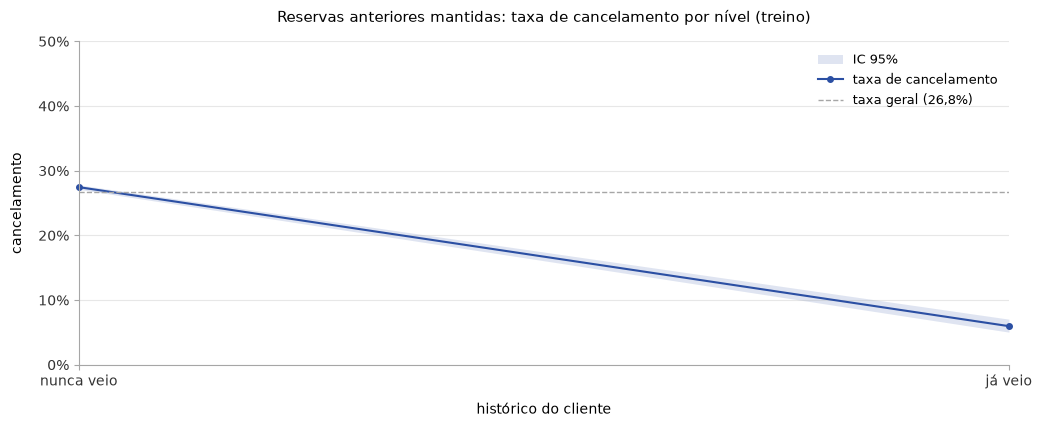

previous_bookings_not_canceled,n,pct_base,taxa,ic_inf,ic_sup,taxa_2015,taxa_2016
nunca veio,65308,0.9682,0.2745,0.2711,0.2780,0.2499,0.2838
já veio,2147,0.0318,0.0596,0.0504,0.0704,0.0651,0.0587


In [55]:
# limites para o pd.cut: (-1, 0] = nunca veio | (0, inf) = já veio
conferir_faixas('previous_bookings_not_canceled', [-1, 0, np.inf], ['nunca veio', 'já veio'],
                'Reservas anteriores mantidas: taxa de cancelamento por nível (treino)', 'histórico do cliente')

**Leitura.**

- **Quem já veio cancela 6,0%, contra 27,5% de quem nunca veio.** É a maior diferença entre as variáveis sim ou não.
- **A ordem se mantém nos dois anos:** 25,0% e 6,5% em 2015; 28,4% e 5,9% em 2016.
- **Referência: nunca veio**, o nível maior (96,8% do treino).
- **Para a apresentação:** "cliente que já veio e manteve a reserva quase nunca cancela".

#### Dias em lista de espera: logito de p por faixa

Quase todas as reservas não passam pela lista de espera. As demais são agrupadas em 1 a 7 dias, 8 a 30 e mais de 30.

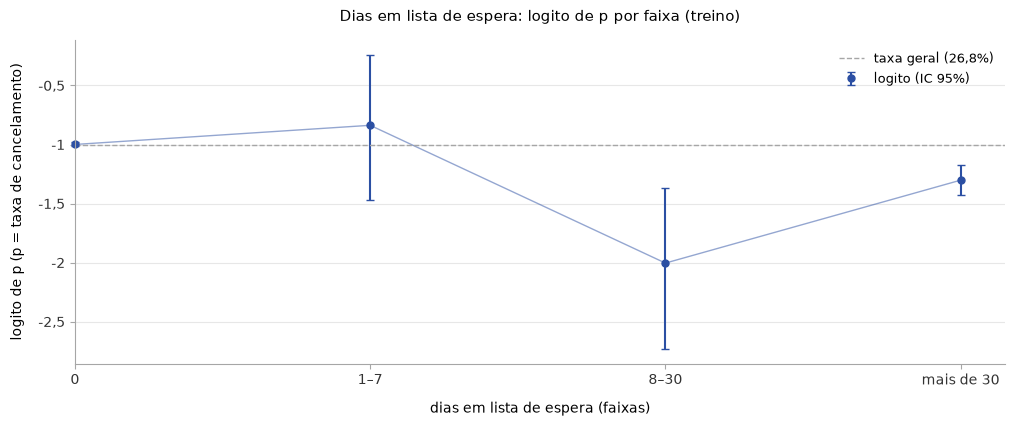

dias_lista_espera,n,taxa,ic_inf,ic_sup,logito,taxa_2015,taxa_2016
0,65892,0.2690,0.2656,0.2724,-0.9996,0.2542,0.2744
1–7,47,0.2979,0.1865,0.4398,-0.8374,0,0.3784
8–30,79,0.1139,0.0611,0.2025,-2.0043,0,0.1875
mais de 30,1437,0.2136,0.1932,0.2356,-1.3019,0.0339,0.3284


In [56]:
# dias em lista de espera: logito de p por faixa (treino)
logito_por_valor('days_in_waiting_list', [-1, 0, 7, 30, np.inf], ['0', '1–7', '8–30', 'mais de 30'],
                 'Dias em lista de espera: logito de p por faixa (treino)', 'dias em lista de espera (faixas)',
                 'dias_lista_espera')

**Leitura.**

- **Só 1.563 reservas passaram pela lista de espera** (2,3% do treino), quase todas por mais de 30 dias (1.437 reservas, com 21,4% de cancelamento, contra 26,9% sem espera).
- **O padrão vira entre os anos:** mais de 30 dias de espera cancelam 3,4% em 2015 e 32,8% em 2016, contra 25,4% e 27,4% sem espera.

#### Dias em lista de espera: árvore de decisão

A mesma árvore, com as mesmas regras de parada.

In [57]:
# dias em lista de espera: os passos da árvore (treino)
passos_espera = cortes_por_ganho(treino, 'days_in_waiting_list')
display(passos_espera)
primeiro = passos_espera.iloc[0]
ganho_espera = f"{primeiro['ganho']:.5f}".replace('.', ',')
print(f"Cortes aceitos: {(passos_espera['aceito'] == 'sim').sum()}. O melhor primeiro corte ({primeiro['corte_novo']} dias) "
      f"teria ganho de {ganho_espera}, abaixo do mínimo de 0,0005.")

faixas,corte_novo,ganho,ganho_acumulado,aceito,cortes
2,32,0.0004,0.0004,não,32
3,97,0.0010,0.0014,não,"32, 97"
4,60,< 0.0001,0.0015,não,"32, 60, 97"


Cortes aceitos: 0. O melhor primeiro corte (32 dias) teria ganho de 0,00038, abaixo do mínimo de 0,0005.


**Leitura.**

- **A árvore não faz nenhum corte:** o melhor primeiro corte, em 32 dias, teria ganho de 0,00038, abaixo do mínimo. Os passos seguintes aparecem na tabela, mas a árvore já parou no primeiro.
- **Proposta: sai.** Separa pouco, atinge 2,3% das reservas e muda de sentido entre os anos.

#### Cancelamentos anteriores: logito de p por valor

Um ponto por número de cancelamentos anteriores; o último junta 2 ou mais.

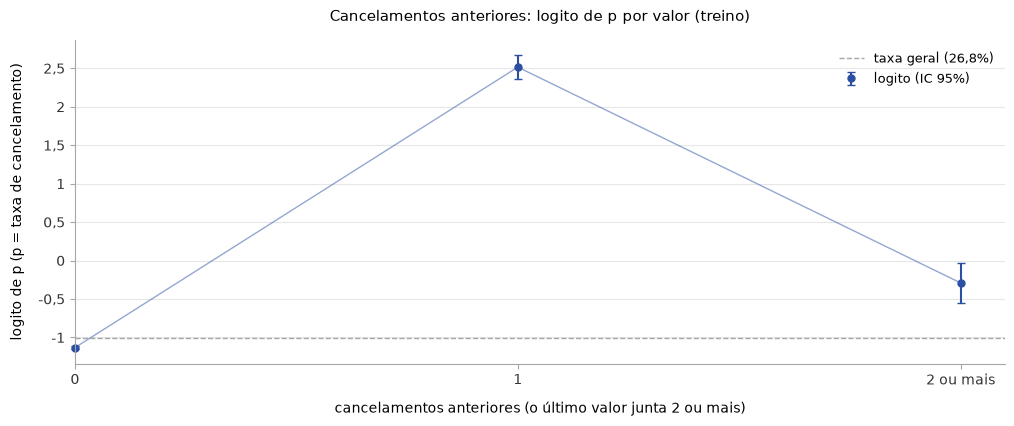

cancelamentos_anteriores,n,taxa,ic_inf,ic_sup,logito,taxa_2015,taxa_2016
0,64902,0.2436,0.2403,0.2469,-1.1330,0.1605,0.2713
1,2319,0.9254,0.9140,0.9354,2.5154,0.9838,0.6938
2 ou mais,234,0.4274,0.3656,0.4914,-0.2914,0.7879,0.2857


In [58]:
# cancelamentos anteriores: logito de p por valor (treino)
logito_por_valor('previous_cancellations', [-1, 0, 1, np.inf], ['0', '1', '2 ou mais'],
                 'Cancelamentos anteriores: logito de p por valor (treino)',
                 'cancelamentos anteriores (o último valor junta 2 ou mais)', 'cancelamentos_anteriores')

**Leitura.**

- **Um cancelamento anterior cancela 92,5%**, contra 24,4% sem nenhum. Com 2 ou mais, 42,7%: menos que com um só, o que não segue escada nenhuma.
- **Em 2015, um cancelamento anterior cancela 98,4%; em 2016, 69,4%.** Uma taxa perto de 100% numa variável de histórico é suspeita. Examinada abaixo.

#### Cancelamentos anteriores: árvore e conferência por ano

A árvore e a conferência em 2015 e 2016, como nas outras variáveis.

In [59]:
# cancelamentos anteriores: a árvore e a conferência por ano (treino)
passos_cancelamentos = cortes_por_ganho(treino, 'previous_cancellations')
display(passos_cancelamentos)
cortes_cancelamentos, conferencia_cancelamentos, _ = conferir_cortes_por_periodo(treino, 'previous_cancellations',
                                                                                 passos_cancelamentos)
display(conferencia_cancelamentos.round(4))

faixas,corte_novo,ganho,ganho_acumulado,aceito,cortes
2,0,0.0474,0.0474,sim,0


rodada,faixa,taxa_2015,taxa_2016,mesma_ordem
1,0,0.1605,0.2713,
1,mais de 0,0.9771,0.5858,sim


**Leitura.**

- **A árvore faz um corte: nunca cancelou × já cancelou**, com ganho de 0,0474, o maior de todas as variáveis (o primeiro corte da antecedência tem 0,0319). Não há segundo corte: "2 ou mais" tem menos reservas que o mínimo de uma faixa.
- **O corte vale nos dois anos:** já cancelou cancela 97,7% em 2015 e 58,6% em 2016, contra 16,1% e 27,1%.
- **Pelo método, entraria.** Antes, a suspeita de vazamento.

#### Cancelamentos anteriores: suspeita de vazamento

Taxa de cancelamento de quem já cancelou e de quem nunca cancelou, separando as reservas de blocos (com linha idêntica na base, notebook 01, seção 4.2), em cada ano do treino.

In [60]:
# cancelamentos anteriores: blocos × demais reservas, em cada ano (treino)
suspeita = treino.assign(
    cancelou_antes=np.where(treino['previous_cancellations'] > 0, 'já cancelou', 'nunca cancelou'),
    bloco=np.where(treino['tem_gemea'], 'com linha idêntica', 'sem linha idêntica'),
)
tabela = suspeita.groupby(['cancelou_antes', 'bloco', 'arrival_date_year'])['is_canceled'].agg(reservas='size', taxa='mean').unstack()
tabela.columns = [f'{a}_{b}' for a, b in tabela.columns]
tabela.round(4)

cancelou_antes,bloco,reservas_2015,reservas_2016,taxa_2015,taxa_2016
já cancelou,com linha idêntica,1361,210,1,1
já cancelou,sem linha idêntica,557,425,0.9210,0.3812
nunca cancelou,com linha idêntica,5408,11005,0.1967,0.3368
nunca cancelou,sem linha idêntica,10819,37670,0.1423,0.2522


**Leitura.**

- **Nos blocos, todas as reservas com cancelamento anterior cancelaram:** 100% em 2015 (1.361 reservas) e em 2016 (210). Comportamento de cliente não dá 100% exato em mais de mil casos.
- **Explicação provável:** quando um grupo cancela um bloco de quartos, o sistema conta os outros quartos cancelados como "cancelamentos anteriores" do mesmo cliente. A contagem nasce junto com o cancelamento e carrega a resposta. A base guarda o valor final da coluna, e não o valor na hora da reserva, então não dá para confirmar sem o sistema do hotel.
- **Fora dos blocos, o sinal parece real, mas instável:** 92,1% em 2015 e 38,1% em 2016, com menos de mil reservas.
- **Proposta: sai, por suspeita de vazamento**, como as reservas com zero noites no notebook 01. O cliente que volta continua representado por "já veio × nunca veio".

### 3.10 Hotel

As categóricas seguem o mesmo método das numéricas, com a função `agrupar_categorias`:

1. as categorias com menos de 0,5% do treino se juntam em "outras";
2. as categorias são ordenadas pela taxa de cancelamento, e a árvore de decisão procura onde cortar essa ordem;
3. cada corte precisa manter a ordem em 2015 e em 2016; os que invertem saem;
4. quando sobra mais de um agrupamento possível, o AIC e o BIC comparam as opções.

O hotel é a primeira.

#### Taxa por categoria e agrupamento

Taxa de cada categoria no treino e em cada ano, na ordem da taxa, com o grupo que sobra depois da árvore e da conferência por ano.

In [61]:
def mostrar_agrupamento(coluna):
    grupo, tabela, saidas = agrupar_categorias(treino, coluna)
    display(tabela.round(4))
    print('\n'.join(saidas) if saidas else 'Todos os cortes da árvore valem nos dois anos.')
    return grupo

# hotel: taxa por categoria e agrupamento pela árvore, conferido em 2015 e 2016 (treino)
grupo_hotel = mostrar_agrupamento('hotel')

hotel,reservas,pct_base,taxa,taxa_2015,taxa_2016,grupo
Resort Hotel,25018,0.3709,0.2280,0.2111,0.2355,Resort Hotel
City Hotel,42437,0.6291,0.2911,0.2730,0.2970,City Hotel


Todos os cortes da árvore valem nos dois anos.


**Leitura.**

- **O hotel urbano cancela mais:** 29,1%, contra 22,8% do resort.
- **A ordem se mantém nos dois anos:** 27,3% e 21,1% em 2015; 29,7% e 23,6% em 2016.
- **Proposta: entra. Referência: urbano**, o maior (62,9% do treino).

### 3.11 Segmento de mercado

Por onde a reserva chega: agência online, operadora ou agência tradicional, grupos, direto, corporativo, cortesia e outros.

#### Taxa por categoria e agrupamento

Taxa de cada categoria no treino e em cada ano, na ordem da taxa, com o grupo que sobra depois da árvore e da conferência por ano.

In [62]:
# segmento de mercado: taxa por categoria e agrupamento pela árvore, conferido em 2015 e 2016 (treino)
grupo_segmento = mostrar_agrupamento('market_segment')

market_segment,reservas,pct_base,taxa,taxa_2015,taxa_2016,grupo
Complementary,509,0.0075,0.1120,0.0932,0.1207,"Complementary, Corporate, Direct, Offline TA/TO, outras"
Corporate,3531,0.0523,0.1323,0.1529,0.1229,"Complementary, Corporate, Direct, Offline TA/TO, outras"
Direct,7848,0.1163,0.1534,0.1534,0.1534,"Complementary, Corporate, Direct, Offline TA/TO, outras"
Offline TA/TO,14545,0.2156,0.1743,0.1940,0.1641,"Complementary, Corporate, Direct, Offline TA/TO, outras"
outras,125,0.0019,0.2320,,0.2320,"Complementary, Corporate, Direct, Offline TA/TO, outras"
Groups,7401,0.1097,0.3167,0.3781,0.2586,"Groups, Online TA"
Online TA,33496,0.4966,0.3409,0.2680,0.3571,"Groups, Online TA"


Todos os cortes da árvore valem nos dois anos.


**Leitura.**

- **Agência online e grupos cancelam mais:** 34,1% e 31,7%. Operadora tradicional, direto, corporativo e cortesia ficam entre 11,2% e 17,4%. Aviação e Undefined (125 reservas) se juntam em "outras".
- **A árvore faz um corte:** agência online e grupos × os demais.
- **Grupos e agência online não se separam de forma estável:** em 2015, grupos cancelam 37,8%, mais que a agência online (26,8%); em 2016, 25,9%, menos (35,7%).

#### Segmento: comparação das opções

Os segmentos todos separados (com aviação e Undefined em "outras"), o agrupamento da árvore e o modelo sem nenhuma variável.

In [63]:
# segmento: todos separados × agrupamento da árvore (treino)
pequenos = treino['market_segment'].value_counts(normalize=True).loc[lambda p: p < 0.005].index
treino = treino.assign(segmento_todos=treino['market_segment'].where(~treino['market_segment'].isin(pequenos), 'outras'),
                       segmento=grupo_segmento)
comparar_cortes(treino, 'adults', {}, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    'todos os segmentos': 'is_canceled ~ C(segmento_todos)',
    'árvore: agência online e grupos × demais': 'is_canceled ~ C(segmento)',
})[['n_coeficientes', 'AIC', 'dif_AIC', 'BIC', 'dif_BIC']]

opcao,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC
todos os segmentos,6,75677.5000,0,75741.3000,0
árvore: agência online e grupos × demais,1,75742.3000,64.9000,75760.6000,19.3000
sem nenhuma variável,0,78375.6000,2698.1000,78384.7000,2643.4000


**Leitura.**

- **Todos os segmentos separados ganham pelo BIC, por 19,3 pontos**, mas não passam na conferência por ano: grupos e agência online trocam de lugar entre 2015 e 2016 (acima).
- **Proposta: dois grupos, "agência online e grupos" × "demais"** (direto, corporativo, operadora, cortesia e outras). **Referência: agência online e grupos**, o maior (60,6% do treino).
- **Grupos têm um comportamento próprio**, ligado aos blocos de quartos (seção 3.1).

### 3.12 Canal de distribuição

Por onde a reserva é feita: agência ou operadora (TA/TO), direto, corporativo e outros.

#### Taxa por categoria e agrupamento

Taxa de cada categoria no treino e em cada ano, na ordem da taxa, com o grupo que sobra depois da árvore e da conferência por ano.

In [64]:
# canal de distribuição: taxa por categoria e agrupamento pela árvore, conferido em 2015 e 2016 (treino)
grupo_canal = mostrar_agrupamento('distribution_channel')

distribution_channel,reservas,pct_base,taxa,taxa_2015,taxa_2016,grupo
Direct,9060,0.1343,0.1517,0.1447,0.1545,"Direct, Corporate, outras"
Corporate,4381,0.0649,0.1586,0.1429,0.1649,"Direct, Corporate, outras"
outras,104,0.0015,0.2115,0,0.2157,"Direct, Corporate, outras"
TA/TO,53910,0.7992,0.2961,0.2746,0.3039,TA/TO


Todos os cortes da árvore valem nos dois anos.


**Leitura.**

- **A árvore faz um corte: agência ou operadora (TA/TO) × direto e corporativo.** TA/TO cancela 29,6%; direto e corporativo, 15,2% e 15,9%. O corte vale nos dois anos.
- **O canal repete parte do segmento:** TA/TO junta a agência online (34,1%) e a operadora tradicional (17,4%).
- **Proposta: candidata.** O `03_variaveis_em_conjunto.ipynb` confere se o canal repete outras variáveis (multicolinearidade).

### 3.13 Tipo de cliente

Avulso (Transient), avulso ligado a outra reserva (Transient-Party), contrato (Contract) e grupo (Group).

#### Taxa por categoria e agrupamento

Taxa de cada categoria no treino e em cada ano, na ordem da taxa, com o grupo que sobra depois da árvore e da conferência por ano.

In [65]:
# tipo de cliente: taxa por categoria e agrupamento pela árvore, conferido em 2015 e 2016 (treino)
grupo_tipo_cliente = mostrar_agrupamento('customer_type')

customer_type,reservas,pct_base,taxa,taxa_2015,taxa_2016,grupo
Group,344,0.0051,0.1279,0.1789,0.0649,"Group, Contract, Transient-Party, Transient"
Contract,2852,0.0423,0.2248,0.2461,0.1651,"Group, Contract, Transient-Party, Transient"
Transient-Party,17770,0.2634,0.2421,0.2816,0.2184,"Group, Contract, Transient-Party, Transient"
Transient,46489,0.6892,0.2811,0.2230,0.2954,"Group, Contract, Transient-Party, Transient"


O corte entre Transient-Party e Transient inverte a ordem entre os períodos e sai.


**Leitura.**

- **As taxas vão de 12,8% (grupo) a 28,1% (avulso).**
- **O único corte da árvore inverte entre os anos:** o avulso ligado a outra reserva cancela 28,2% em 2015, mais que o avulso (22,3%), e 21,8% em 2016, menos (29,5%).
- **Proposta: sai.** Nenhum agrupamento vale nos dois anos. A questão do nível Group, pequeno e diferente dos outros, deixa de existir.

### 3.14 Regime de refeição

Café da manhã (BB), meia pensão (HB), pensão completa (FB), sem refeição (SC) e não informado (Undefined).

#### Taxa por categoria e agrupamento

Taxa de cada categoria no treino e em cada ano, na ordem da taxa, com o grupo que sobra depois da árvore e da conferência por ano.

In [66]:
# regime de refeição: taxa por categoria e agrupamento pela árvore, conferido em 2015 e 2016 (treino)
grupo_regime = mostrar_agrupamento('meal')

meal,reservas,pct_base,taxa,taxa_2015,taxa_2016,grupo
Undefined,642,0.0095,0.1324,0.1118,0.1398,"Undefined, HB, BB, SC, FB"
HB,8311,0.1232,0.2328,0.2577,0.2187,"Undefined, HB, BB, SC, FB"
BB,52719,0.7815,0.2651,0.2482,0.2714,"Undefined, HB, BB, SC, FB"
SC,5375,0.0797,0.3548,0.0863,0.3760,"Undefined, HB, BB, SC, FB"
FB,408,0.0060,0.3750,0.4058,0.3433,"Undefined, HB, BB, SC, FB"


O corte entre HB e BB inverte a ordem entre os períodos e sai.
O corte entre BB e SC inverte a ordem entre os períodos e sai.


**Leitura.**

- **Todos os cortes da árvore invertem entre os anos.** O caso mais forte é SC: cancela 8,6% em 2015 e 37,6% em 2016.
- **Proposta: sai.** Nenhum agrupamento vale nos dois anos.

### 3.15 Tipo de quarto reservado

O tipo de quarto pedido na reserva, em código anônimo (A, B, C...). É conhecido na reserva e não depende do preço.

#### Taxa por categoria e agrupamento

Taxa de cada categoria no treino e em cada ano, na ordem da taxa, com o grupo que sobra depois da árvore e da conferência por ano.

In [67]:
# tipo de quarto reservado: taxa por categoria e agrupamento pela árvore, conferido em 2015 e 2016 (treino)
grupo_quarto = mostrar_agrupamento('reserved_room_type')

reserved_room_type,reservas,pct_base,taxa,taxa_2015,taxa_2016,grupo
C,443,0.0066,0.2280,0.2229,0.2310,"C, E, A, F, D, B, G, outras, H"
E,3717,0.0551,0.2446,0.2102,0.2561,"C, E, A, F, D, B, G, outras, H"
A,47631,0.7061,0.2613,0.2622,0.2609,"C, E, A, F, D, B, G, outras, H"
F,1781,0.0264,0.2852,0.1553,0.3190,"C, E, A, F, D, B, G, outras, H"
D,11353,0.1683,0.2882,0.1723,0.3152,"C, E, A, F, D, B, G, outras, H"
B,897,0.0133,0.2988,0.2762,0.3070,"C, E, A, F, D, B, G, outras, H"
G,1244,0.0184,0.3272,0.2615,0.3445,"C, E, A, F, D, B, G, outras, H"
outras,6,0.0001,0.3333,0.3333,,"C, E, A, F, D, B, G, outras, H"
H,383,0.0057,0.3760,0.3125,0.3927,"C, E, A, F, D, B, G, outras, H"


O corte entre A e F inverte a ordem entre os períodos e sai.


**Leitura.**

- **O tipo de quarto separa pouco:** a maioria dos tipos fica entre 24% e 30%. O tipo A, com 70,6% do treino, cancela 26,1%.
- **O único corte da árvore inverte entre os anos:** os tipos acima de A na ordem, como D e F, cancelam menos que A em 2015 (17,2% e 15,5%, contra 26,2%) e mais em 2016 (31,5% e 31,9%, contra 26,1%).
- **Proposta: sai.** Nenhum agrupamento vale nos dois anos.

### 3.16 Mês de chegada

2015 só tem chegadas de julho a dezembro; janeiro a junho aparecem só em 2016.

#### Taxa por categoria e agrupamento

Taxa de cada categoria no treino e em cada ano, na ordem da taxa, com o grupo que sobra depois da árvore e da conferência por ano.

In [68]:
# mês de chegada: taxa por categoria e agrupamento pela árvore, conferido em 2015 e 2016 (treino)
grupo_mes = mostrar_agrupamento('arrival_date_month')

arrival_date_month,reservas,pct_base,taxa,taxa_2015,taxa_2016,grupo
January,2023,0.0300,0.1760,,0.1760,"January, November, March"
November,5944,0.0881,0.2281,0.1794,0.2573,"January, November, March"
March,4192,0.0621,0.2297,,0.2297,"January, November, March"
February,3354,0.0497,0.2475,,0.2475,"February, September, May, October, April, June, December"
September,8518,0.1263,0.2537,0.2286,0.2749,"February, September, May, October, April, June, December"
May,4683,0.0694,0.2607,,0.2607,"February, September, May, October, April, June, December"
October,9196,0.1363,0.2609,0.1717,0.3246,"February, September, May, October, April, June, December"
April,4453,0.0660,0.2609,,0.2609,"February, September, May, October, April, June, December"
June,4285,0.0635,0.2618,,0.2618,"February, September, May, October, April, June, December"
December,5977,0.0886,0.2771,0.2041,0.3257,"February, September, May, October, April, June, December"


Todos os cortes da árvore valem nos dois anos.


**Leitura.**

- **A árvore forma três temporadas:** baixa (janeiro, março e novembro), média (fevereiro, abril a junho, setembro, outubro e dezembro) e alta (julho e agosto).
- **Os cortes valem nos dois anos** (temporadas finais, abaixo). Janeiro a junho só aparecem em 2016.

#### Mês: comparação das opções

Os 12 meses, as três temporadas da árvore, julho e agosto × resto do ano, três temporadas fixas (julho e agosto, abril a junho, setembro a março) e o modelo sem nenhuma variável.

In [69]:
# mês: temporadas comparadas (treino)
alta = {'July': 'jul–ago', 'August': 'jul–ago'}
treino = treino.assign(
    temporada=grupo_mes,
    temporada_jul_ago=treino['arrival_date_month'].map(alta).fillna('resto do ano'),
    temporada_fixa=treino['arrival_date_month'].map({**alta, 'April': 'abr–jun', 'May': 'abr–jun', 'June': 'abr–jun'}).fillna('set–mar'),
)
comparar_cortes(treino, 'adults', {}, formulas={
    'sem nenhuma variável': 'is_canceled ~ 1',
    '12 meses': 'is_canceled ~ C(arrival_date_month)',
    'árvore: três temporadas': 'is_canceled ~ C(temporada)',
    'julho e agosto × resto do ano': 'is_canceled ~ C(temporada_jul_ago)',
    'três temporadas fixas: jul–ago / abr–jun / set–mar': 'is_canceled ~ C(temporada_fixa)',
})[['n_coeficientes', 'AIC', 'dif_AIC', 'BIC', 'dif_BIC']]

opcao,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC
12 meses,11,77952.3000,0,78061.7000,56
árvore: três temporadas,2,77978.3000,26.1000,78005.7000,0
três temporadas fixas: jul–ago / abr–jun / set–mar,2,78053.3000,101.1000,78080.7000,75
julho e agosto × resto do ano,1,78060.5000,108.3000,78078.8000,73.1000
sem nenhuma variável,0,78375.6000,423.3000,78384.7000,379


**Leitura.**

- **As três temporadas da árvore são a melhor opção pelo BIC.** Os 12 meses ficam 56,0 pontos atrás: aprendem oscilações de um ano só.
- **"Julho e agosto × resto do ano" fica 73,1 pontos atrás,** e as três temporadas fixas, 75,0. Nas fixas, abril a junho não existe em 2015, e a conferência por ano não pode ser feita.
- **Proposta: três temporadas: baixa, média e alta.**

#### Temporadas finais

Taxa de cada temporada no treino, com o intervalo de confiança, e em cada ano.

In [70]:
# temporadas finais: taxa no treino e em cada ano
nomes_temporada = {'January, November, March': 'baixa', 'August, July': 'alta'}
treino = treino.assign(temporada=pd.Categorical(treino['temporada'].map(nomes_temporada).fillna('média'),
                                                categories=['média', 'baixa', 'alta']))
tabela = taxa_por_nivel(treino, 'temporada')[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']]
tabela[['taxa_2015', 'taxa_2016']] = treino.groupby(['temporada', 'arrival_date_year'], observed=True)['is_canceled'].mean().unstack()[[2015, 2016]].to_numpy()
tabela.round(4)

temporada,n,pct_base,taxa,ic_inf,ic_sup,taxa_2015,taxa_2016
média,40466,0.5999,0.2607,0.2565,0.2650,0.2012,0.2806
baixa,12159,0.1803,0.2200,0.2127,0.2275,0.1794,0.2291
alta,14830,0.2199,0.3257,0.3182,0.3333,0.3521,0.3087


**Leitura.**

- **Baixa, média e alta cancelam 22,0%, 26,1% e 32,6%.**
- **A ordem se mantém nos dois anos:** 17,9%, 20,1% e 35,2% em 2015; 22,9%, 28,1% e 30,9% em 2016.
- **Referência: média**, a maior (60,0% do treino).
- **Para a apresentação:** "julho e agosto concentram os cancelamentos; janeiro, março e novembro cancelam menos".

### 3.17 Agência e empresa

Os códigos de agência (`agent`) e de empresa (`company`) são anônimos e têm centenas de valores. O que se usa é se a reserva tem agência e se é paga por uma empresa (código preenchido). O vazio quer dizer "sem agência" e "não é paga por empresa" (notebook 01, seção 4.1).

#### Taxa por categoria

Taxa com e sem agência, e com e sem empresa, no treino e em cada ano.

In [71]:
# agência e empresa: códigos anônimos viram sim ou não (treino)
print(f"Códigos no treino: {treino['agent'].nunique()} agências e {treino['company'].nunique()} empresas")
treino = treino.assign(
    tem_agencia=np.where(treino['agent'].notna(), 'com agência', 'sem agência'),
    paga_empresa=np.where(treino['company'].notna(), 'paga por empresa', 'sem empresa'),
)
pd.concat({'agência': agrupar_categorias(treino, 'tem_agencia')[1],
           'empresa': agrupar_categorias(treino, 'paga_empresa')[1]},
          names=['variável', 'nível']).drop(columns='grupo').round(4)

Códigos no treino: 275 agências e 289 empresas


variável,nível,reservas,pct_base,taxa,taxa_2015,taxa_2016
agência,sem agência,9552,0.1416,0.1449,0.1322,0.1500
agência,com agência,57903,0.8584,0.2879,0.2671,0.2955
empresa,paga por empresa,4050,0.0600,0.1143,0.1059,0.1177
empresa,sem empresa,63405,0.9400,0.2775,0.2563,0.2852


**Leitura.**

- **Os códigos saem:** são centenas de agências e empresas anônimas, que não se explicam para a diretoria.
- **Com agência, a reserva cancela 28,8%, contra 14,5% sem.** A ordem se mantém nos dois anos (26,7% e 13,2% em 2015; 29,6% e 15,0% em 2016). Mas quase toda reserva de agência online ou operadora tem agência: a variável repete parte do segmento. **Proposta: candidata;** o `03_variaveis_em_conjunto.ipynb` confere se repete outras variáveis (multicolinearidade).
- **Paga por empresa cancela 11,4%, contra 27,8%.** A ordem se mantém nos dois anos (10,6% e 25,6% em 2015; 11,8% e 28,5% em 2016). **Proposta: entra como "paga por empresa" × não. Referência: sem empresa.**

### 3.18 Hóspede que volta

Se o hóspede já se hospedou antes no hotel (`is_repeated_guest`).

#### Taxa por categoria e agrupamento

Taxa de cada categoria no treino e em cada ano, na ordem da taxa, com o grupo que sobra depois da árvore e da conferência por ano.

In [72]:
treino = treino.assign(hospede_volta=np.where(treino['is_repeated_guest'] == 1, 'sim', 'não'))
# hóspede que volta: taxa por categoria e agrupamento pela árvore, conferido em 2015 e 2016 (treino)
grupo_hospede_volta = mostrar_agrupamento('hospede_volta')

hospede_volta,reservas,pct_base,taxa,taxa_2015,taxa_2016,grupo
sim,2110,0.0313,0.2014,0.5477,0.0838,"sim, não"
não,65345,0.9687,0.2698,0.2376,0.2817,"sim, não"


O corte entre sim e não inverte a ordem entre os períodos e sai.


**Leitura.**

- **O corte inverte entre os anos:** quem volta cancela 54,8% em 2015, mais que os demais (23,8%), e 8,4% em 2016, menos (28,2%).
- **Proposta: sai.** O cliente que volta continua representado por "já veio × nunca veio" (seção 3.9), que vale nos dois anos.

## 4. Resumo

As variáveis, no formato escolhido na seção 3, ficam na função `montar_variaveis` do módulo `funcoes.py`. Os notebooks seguintes usam a mesma função, e os cortes ficam escritos num lugar só. Os cortes são valores fixos (dias, euros, meses, categorias), por isso a função vale para o treino e para o teste.

#### Conferência da função

Cada variável da função comparada com a versão da seção 3: cada nível de uma precisa corresponder a um único nível da outra.

In [73]:
# a função do módulo reproduz os níveis da seção 3? (treino)
modelo = montar_variaveis(treino)
secao_3 = {
    'antecedencia': pd.cut(treino['lead_time'], faixas_lead, labels=rotulos_lead),
    'noites': pd.cut(treino['noites'], faixas_noites, labels=rotulos_noites),
    'diaria': pd.cut(treino['diaria_euro'], [-1, 59, np.inf], labels=['até 59', 'mais de 59']),
    'sozinho': treino['sozinho'], 'duas_criancas': treino['duas_criancas'], 'com_bebe': treino['com_bebe'],
    'pedido_especial': treino['total_of_special_requests'] > 0,
    'ja_veio': treino['previous_bookings_not_canceled'] > 0,
    'hotel': treino['hotel'], 'segmento': treino['segmento'], 'canal': grupo_canal,
    'tem_agencia': treino['tem_agencia'], 'paga_empresa': treino['paga_empresa'], 'temporada': treino['temporada'],
}
# correspondência um a um: o cruzamento das duas versões tem uma só casela preenchida por linha e por coluna
diferentes = [nome for nome, versao in secao_3.items()
              if not (pd.crosstab(modelo[nome], versao).gt(0).sum().sum()
                      == modelo[nome].nunique() == versao.nunique())]
print(f"Variáveis que reproduzem a seção 3: {len(secao_3) - len(diferentes)} de {len(secao_3)}")
print('Diferentes:', ', '.join(diferentes) if diferentes else 'nenhuma')

Variáveis que reproduzem a seção 3: 14 de 14
Diferentes: nenhuma


**Leitura.**

- **A função reproduz as 14 variáveis da seção 3,** com as mesmas reservas em cada nível.

#### Variáveis e níveis

Cada variável, com a situação ao fim da seção 3 ("entra" ou "candidata", que depende do teste com as outras variáveis no modelo), a referência, o tamanho de cada nível e a taxa no treino e em cada ano.

In [74]:
# as variáveis do modelo: níveis, referência e taxa no treino e em cada ano
resumir_variaveis(modelo).round(4)

variavel,nivel,situacao,referencia,n,pct_base,taxa,taxa_2015,taxa_2016
antecedencia,mais de 25,entra,sim,43892,0.6507,0.3272,0.3182,0.3303
antecedencia,0,entra,,4260,0.0632,0.0669,0.0677,0.0665
antecedencia,1–8,entra,,9950,0.1475,0.1149,0.1128,0.1157
antecedencia,9–25,entra,,9353,0.1387,0.2424,0.1834,0.2678
noites,2–3,entra,sim,28827,0.4274,0.2726,0.2636,0.2762
noites,1,entra,,13318,0.1974,0.1961,0.1435,0.2116
noites,4 ou mais,entra,,25310,0.3752,0.2997,0.2720,0.3101
diaria,mais de 59,candidata,sim,56597,0.8390,0.2843,0.2567,0.2939
diaria,até 59,candidata,,10858,0.1610,0.1812,0.2055,0.1697
sozinho,não,entra,sim,53900,0.7991,0.2854,0.2694,0.2911


**Leitura.**

- **9 variáveis entram e 5 são candidatas:** diária, com bebê, pedido especial, canal e tem agência. As candidatas passam pela conferência de multicolinearidade do `03_variaveis_em_conjunto.ipynb` e pelo stepwise do `05_modelo.ipynb`.
- **As que entram somam 13 coeficientes, além do intercepto;** as candidatas acrescentam mais 5.
- **Em todas, a referência é o nível maior, e a ordem dos níveis é a mesma em 2015 e em 2016.**
- **O menor nível é "com bebê", com 654 reservas (1,0% do treino),** acima do mínimo de 0,5% usado nas árvores.

#### Dicionário de dados, terceira versão

A segunda versão (notebook 01, seção 6), revista com a univariada e a bivariada. **Entra** quer dizer que a forma está decidida; **candidata**, que a variável segue com uma ressalva. As duas passam pela conferência de multicolinearidade do `03_variaveis_em_conjunto.ipynb` e pelo stepwise do `05_modelo.ipynb`. As taxas são do treino.

| Variável | Decisão | Forma no modelo | Por quê |
| :--- | :--- | :--- | :--- |
| `lead_time` | entra | `antecedencia`: 0 / 1–8 / 9–25 / mais de 25 dias (ref.) | Não é linear no logito. A taxa sobe nas quatro faixas: 6,7%, 11,5%, 24,2% e 32,7%. Os cortes em 257 e 315 dias invertem entre 2015 e 2016 e saem (3.1). |
| `stays_*_nights` | entra | `noites`: 1 / 2–3 (ref.) / 4 ou mais | 19,6%, 27,3% e 30,0%, na mesma ordem nos dois anos (3.2). |
| `adr` | candidata | `diaria`: até 59 € / mais de 59 € (ref.) | 18,1% contra 28,4%. Sobe em 2017 também por preço, e as faixas em euros envelhecem (3.3 e notebook 04). |
| `adults` | entra | `sozinho`: sim / não (ref.) | Quem viaja sozinho cancela 19,7%, contra 28,5% (3.4 e 3.7). |
| `children` | entra | `duas_criancas`: sim / não (ref.) | Duas crianças ou mais cancelam 38,2%, contra 26,4%. "Com criança" (1 ou mais) inverte entre os anos (3.5 e 3.7). |
| `babies` | candidata | `com_bebe`: sim / não (ref.) | 20,8% contra 26,8%. 84,7% das reservas com bebê fizeram pedido especial: o efeito pode ser do pedido (3.6 e 3.7). |
| `total_of_special_requests` | candidata | `pedido_especial`: fez pedido / nenhum (ref.) | 18,8% contra 33,0%. Pode mudar até a chegada: depende do momento do score (3.8). |
| `previous_bookings_not_canceled` | entra | `ja_veio`: já veio / nunca veio (ref.) | 6,0% contra 27,5%, a maior diferença entre as variáveis sim ou não (3.9). |
| `previous_cancellations` | **sai** | | Suspeita de vazamento: nos blocos, 100% das reservas com cancelamento anterior cancelaram, em 2015 e em 2016 (3.9). |
| `days_in_waiting_list` | **sai** | | A árvore não faz nenhum corte, e a espera longa cancela 3,4% em 2015 e 32,8% em 2016 (3.9). |
| `hotel` | entra | `hotel`: urbano (ref.) / resort | 29,1% contra 22,8% (3.10). |
| `market_segment` | entra | `segmento`: agência online e grupos (ref.) / demais | Agência online e grupos cancelam 34,1% e 31,7%; os demais, de 11,2% a 17,4%. Separar os segmentos não vale nos dois anos (3.11). |
| `distribution_channel` | candidata | `canal`: agência ou operadora (ref.) / demais | 29,6% contra 15,2% a 15,9%. Repete parte do segmento (3.12). |
| `customer_type` | **sai** | | O único corte inverte entre os anos (3.13). |
| `meal` | **sai** | | Todos os cortes invertem entre os anos; SC cancela 8,6% em 2015 e 37,6% em 2016 (3.14). |
| `reserved_room_type` | **sai** | | O único corte inverte entre os anos (3.15). |
| `arrival_date_month` | entra | `temporada`: baixa (jan, mar, nov) / média (ref.) / alta (jul, ago) | 22,0%, 26,1% e 32,6%, na mesma ordem nos dois anos (3.16). |
| `agent` | candidata | `tem_agencia`: com agência (ref.) / sem agência | 28,8% contra 14,5%. Repete parte do segmento (3.17). |
| `company` | entra | `paga_empresa`: paga por empresa / sem empresa (ref.) | 11,4% contra 27,8% (3.17). |
| `is_repeated_guest` | **sai** | | Inverte entre os anos; o cliente que volta fica representado por `ja_veio` (3.18). |
| `is_canceled` | resposta | 1 = cancelada, 0 = veio | 26,8% no treino. |

## Decisões para o grupo

*Seção temporária: cada ponto sai daqui quando o grupo decidir. A comparação completa com os notebooks do grupo está em `comparacao_decisoes.md`. Os pontos de escopo e limpeza estão no fim do `01_exploratoria.ipynb`.*

| # | Decisão | Proposta deste notebook | Evidência | Notebooks do grupo |
| --- | --- | --- | --- | --- |
| 1 | **Faixas de antecedência** | Cortes da árvore de decisão (ganho de informação), conferidos em 2015 e 2016: 0, 1–8, 9–25 e mais de 25 dias, com mais de 25 como referência. Os cortes em 257 e 315 dias invertem a ordem entre os anos e saem | 3.1 | `TODO.md` e dicionário: até 7, 8–30, 31–90, 91–180 e mais de 180 dias (62,0 pontos de BIC atrás da árvore conferida) |
| 2 | **Faixas de noites** | Cortes da árvore de decisão: 1, 2–3 e 4 ou mais noites, com 2–3 como referência. As reservas com zero noites saíram da base (notebook 01, seção 4.4) | 3.2 | Dicionário: até 1 (com as zero noites), 2–3, 4–7 e mais de 7. Notebook 03: zero noites numa faixa própria |
| 3 | **`previous_cancellations`** | Sai, por suspeita de vazamento: nas reservas de blocos (com linha idêntica), 100% das que têm cancelamento anterior cancelaram, em 2015 e em 2016. A contagem parece gravada junto com o cancelamento do próprio bloco. Pelo método, seria a variável mais forte (ganho de 0,0474) | 3.9 | Testar: já cancelou × nunca cancelou |
| 4 | **Adultos, crianças e bebês** | Sozinho (1 adulto) e 2 ou mais crianças entram. Com bebê fica como candidata: com adultos e crianças no modelo, melhora o BIC em 9,0 pontos, mas 84,7% das reservas com bebê fizeram pedido especial, e o efeito pode ser do pedido; o stepwise do 05 decide. Uma variável única de composição fica 3,9 pontos de BIC atrás; "com criança × sem" (1 ou mais) inverte entre os anos | 3.4 a 3.7 | `com_crianca` (com × sem) soma crianças e bebês |
| 5 | **`meal`** | Sai: nenhum agrupamento vale nos dois anos. SC cancela 8,6% em 2015 e 37,6% em 2016 | 3.14 | Sem refeição (SC e Undefined) × com refeição |
| 6 | **Temporadas** | Três, pela árvore: baixa (janeiro, março e novembro), média (os demais meses fora do verão) e alta (julho e agosto). As três do grupo ficam 75,0 pontos de BIC atrás, e abril a junho não existe em 2015 | 3.16 | Três: jul–ago, abr–jun e set–mar |
| 7 | **`customer_type`** | Sai: o único corte da árvore (avulso × avulso ligado a outra reserva) inverte entre 2015 e 2016 | 3.13 | Entra |
| 8 | **`company`** | Entra como "paga por empresa" × não: 11,4% contra 27,8%, com a ordem mantida nos dois anos | 3.17 | Sai |
| 9 | **`adr`** | Candidata como até 59 € × mais de 59 € (diária arredondada para o euro), com mais de 59 como referência. Da árvore saem os cortes que criam faixas de menos de 10 € (tarifas de grupos, operadoras e empresas) e o de 115 €, que inverte entre 2015 e 2016. O stepwise do `05_modelo.ipynb` decide se a diária entra | 3.3 | Entra como número (155,6 pontos de BIC atrás das 2 faixas) |
| 10 | **Uso do teste** | O teste (2017) não entra em nenhuma escolha de cortes ou de variáveis; a estabilidade é conferida entre 2015 e 2016, dentro do treino. A decomposição da alta de 2017 sai deste notebook e fica para o `05_modelo`, depois da avaliação | 1 e 3 | Notebook 03 do grupo: decomposição da alta de 2017 antes do modelo |
| 11 | **Segmento** | Dois grupos, pela árvore: agência online e grupos × demais (direto, corporativo, operadora, cortesia e outros). Separar todos os segmentos não vale nos dois anos: grupos cancelam mais que a agência online em 2015 e menos em 2016 | 3.11 | Todos os segmentos, com cortesia, aviação e Undefined em "Outros" |
| 12 | **Pedido especial** | Candidata, como fez pedido × nenhum: 18,8% contra 33,0%, com a ordem mantida nos dois anos. Só pode entrar se o score for calculado depois da reserva, porque o pedido pode ser feito até a chegada (notebook 01, Decisões, item 8). O 05 compara o modelo com e sem | 3.8 | Em teste, junto com o momento do score |
